# Atividade de Machine Learning: classificação e regressão

**Aluno:** Vinícius

Este notebook resolve as duas partes da atividade:

- **Parte 1, classificação:** identificar se um tumor de mama é benigno ou maligno a partir de medidas extraídas de exames (dataset *Breast Cancer Wisconsin*).
- **Parte 2, regressão:** prever o valor de imóveis com Regressão Linear (dataset *California Housing*).

A ordem das seções é a mesma da estrutura pedida no enunciado. Da seção 3 à 7, cada etapa tem uma subseção para cada parte. Assim dá para ver o mesmo passo (carregar, explorar, preparar, treinar, avaliar) nos dois problemas, um logo depois do outro.

**Sumário**

1. Introdução
2. Importação das bibliotecas
3. Carregamento dos dados
4. Análise exploratória
5. Pré-processamento
6. Treinamento dos modelos
7. Avaliação dos resultados
8. Conclusão

## 1. Introdução

Em aprendizado supervisionado, os dois tipos de problema mais comuns são a **classificação**, em que o alvo é uma categoria, e a **regressão**, em que o alvo é um número contínuo. A atividade pede um exemplo de cada.

**Parte 1: diagnóstico de câncer de mama.** O *Breast Cancer Wisconsin (Diagnostic)* foi montado na Universidade de Wisconsin no início dos anos 90. Cada um dos 569 registros corresponde a uma amostra coletada por punção aspirativa com agulha fina (PAAF). A imagem digitalizada da amostra foi usada para medir os núcleos das células: raio, textura, perímetro, área, concavidade etc. O objetivo é prever se o tumor é **benigno** ou **maligno**. Neste problema os erros não têm o mesmo peso: classificar um tumor maligno como benigno (falso negativo) é bem mais grave do que o contrário. Por isso não vou olhar só para a acurácia.

**Parte 2: preço de imóveis na Califórnia.** O *California Housing* vem do censo americano de 1990. Cada linha **não é uma casa**, e sim um *block group*: um pequeno agrupamento de quarteirões, que normalmente tem de 600 a 3.000 moradores. O alvo é o valor mediano das casas da região, em unidades de US$ 100.000. Escolhi esse dataset porque ele já vem no scikit-learn, tem um tamanho bom (20.640 regiões) e mostra bem onde a Regressão Linear funciona e onde ela começa a falhar.

Todas as etapas aleatórias (divisão treino/teste, validação cruzada, Random Forest) usam a mesma semente, `SEED = 42`, então rodar o notebook de novo gera os mesmos números.

## 2. Importação das bibliotecas

Uso só as bibliotecas sugeridas no enunciado: pandas e numpy para os dados, matplotlib e seaborn para os gráficos e scikit-learn para os modelos e métricas.

In [1]:
# Biblioteca padrão
from pathlib import Path
from platform import python_version

# Manipulação de dados
import numpy as np
import pandas as pd

# Gráficos
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Scikit-learn: datasets, divisão dos dados, modelos e métricas
import sklearn
from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_validate, cross_val_predict, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

SEED = 42  # semente usada em todas as etapas aleatórias

# Tabelas com 3 casas decimais e sem notação científica
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 40)

print(f"Python {python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {mpl.__version__} | seaborn {sns.__version__}")

Python 3.12.16 | pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


### Tema escuro dos gráficos

Todos os gráficos usam o mesmo tema escuro, configurado uma vez só nesta célula. Escolhi as cores para continuarem distinguíveis por quem tem daltonismo. Cada classe tem uma cor fixa no notebook inteiro (**benigno = azul**, **maligno = laranja**). A grade é discreta para não disputar atenção com os dados. Nos mapas de calor, uma escala é **sequencial** (um só tom de azul, do escuro ao claro) e a outra é **divergente** (azul para valores negativos, cinza no zero e vermelho para positivos).

In [2]:
# Paleta do tema escuro
CORES = {
    "fundo": "#1a1a19",
    "texto": "#f0efec",
    "texto_2": "#c3c2b7",
    "apagado": "#898781",
    "grade": "#2c2c2a",
    "eixo": "#383835",
    "azul": "#3987e5",
    "laranja": "#d95926",
    "verde_agua": "#199e70",
    "vermelho": "#e66767",
}
# Cor fixa por classe, usada em todos os gráficos da Parte 1
COR_CLASSE = {"Benigno": CORES["azul"], "Maligno": CORES["laranja"]}

# Mapas de cor: sequencial (um tom só, escuro -> claro) e divergente (azul <- cinza -> vermelho)
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "seq_azul", ["#0d366b", "#256abf", "#5598e7", "#9ec5f4", "#e3eefc"])
CMAP_DIV = LinearSegmentedColormap.from_list(
    "div_azul_vermelho", [CORES["azul"], CORES["eixo"], CORES["vermelho"]])

sns.set_theme(context="notebook", palette=[CORES["azul"], CORES["laranja"], CORES["verde_agua"]])
plt.rcParams.update({
    "figure.facecolor": CORES["fundo"],
    "savefig.facecolor": CORES["fundo"],
    "axes.facecolor": CORES["fundo"],
    "axes.edgecolor": CORES["eixo"],
    "axes.labelcolor": CORES["texto_2"],
    "axes.titlecolor": CORES["texto"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": CORES["grade"],
    "grid.linestyle": "-",
    "grid.linewidth": 0.8,
    "text.color": CORES["texto"],
    "xtick.color": CORES["eixo"],
    "ytick.color": CORES["eixo"],
    "xtick.labelcolor": CORES["texto_2"],
    "ytick.labelcolor": CORES["texto_2"],
    "legend.frameon": False,
    "legend.labelcolor": CORES["texto_2"],
    "lines.linewidth": 2,
    "patch.force_edgecolor": False,  # o seaborn coloca borda branca nas barras; aqui não
    "patch.edgecolor": CORES["fundo"],
    "figure.dpi": 110,
    "figure.figsize": (9, 5),
})
%config InlineBackend.figure_format = "retina"

# Contorno escuro nos textos escritos por cima de pontos, para continuarem legíveis
CONTORNO = [pe.withStroke(linewidth=3, foreground=CORES["fundo"])]


def br(valor, casas=1):
    # Formata números com vírgula decimal (padrão brasileiro) nos rótulos dos gráficos
    return f"{valor:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def estilizar_colorbar(cbar, numeros_simples=False):
    # Deixa a barra de cores combinando com o tema (sem contorno branco)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(which="both", colors=CORES["eixo"], labelcolor=CORES["texto_2"])
    cbar.ax.yaxis.label.set_color(CORES["texto_2"])
    if numeros_simples:  # escala log: mostra 1, 10, 100 em vez de 10⁰, 10¹, 10²
        cbar.ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))

## 3. Carregamento dos dados

### 3.1 Parte 1: Breast Cancer Wisconsin

Este dataset vem junto com o scikit-learn e não precisa de internet. Um detalhe que costuma passar batido: no scikit-learn, o rótulo `0` é **maligno** e o `1` é **benigno**. Precision, recall e F1 são calculados por padrão para a classe `1`. Se eu deixasse assim, o recall mediria "quantos tumores *benignos* o modelo encontrou", e não é isso que interessa num diagnóstico.

Por isso inverto a codificação e crio a coluna `diagnostico`: **1 = maligno** (a classe positiva, a que queremos detectar) e **0 = benigno**.

In [3]:
cancer = load_breast_cancer(as_frame=True)

df_cancer = cancer.frame.copy()
# No scikit-learn 0 = malignant e 1 = benign. Aqui passa a ser 1 = maligno (classe positiva).
df_cancer["diagnostico"] = (df_cancer["target"] == 0).astype(int)
df_cancer = df_cancer.drop(columns="target")

NOMES_CLASSES = ["Benigno", "Maligno"]  # posição 0 e 1, igual à codificação de 'diagnostico'

print("Codificação original do scikit-learn:", {i: str(n) for i, n in enumerate(cancer.target_names)})
print("Codificação usada aqui:            ", dict(enumerate(NOMES_CLASSES)))
df_cancer.head()

Codificação original do scikit-learn: {0: 'malignant', 1: 'benign'}
Codificação usada aqui:             {0: 'Benigno', 1: 'Maligno'}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119,1
1,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089,1
2,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088,1
3,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173,1
4,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077,1


### 3.2 Parte 2: California Housing

Este dataset é baixado na primeira execução e depois fica guardado em `~/scikit_learn_data`. Para o notebook não quebrar numa máquina sem internet, ou se o servidor do download estiver fora do ar, deixei no repositório uma cópia em `dados/california_housing.csv`. Ela foi gerada a partir do próprio `fetch_california_housing` e é idêntica a ele. A cópia só é usada se o download falhar.

| Coluna | O que representa |
|---|---|
| `MedInc` | renda mediana das famílias da região (em dezenas de milhares de US$) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | número de moradores da região |
| `AveOccup` | média de moradores por domicílio |
| `Latitude`, `Longitude` | localização da região |
| `MedHouseVal` | **alvo**: valor mediano das casas (em US$ 100.000) |

In [4]:
CSV_CASAS = Path("dados") / "california_housing.csv"


def carregar_california():
    # Tenta o download pelo scikit-learn; se falhar (sem internet, timeout, servidor fora), usa a cópia local
    try:
        return fetch_california_housing(as_frame=True).frame, "scikit-learn (fetch_california_housing)"
    except OSError as erro:
        print(f"Não foi possível baixar o dataset ({type(erro).__name__}: {erro})")
        return pd.read_csv(CSV_CASAS), f"cópia local ({CSV_CASAS})"


df_casas, origem_casas = carregar_california()
print("Origem dos dados:", origem_casas)
df_casas.head()

Origem dos dados: scikit-learn (fetch_california_housing)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


## 4. Análise exploratória

### 4.1 Parte 1: Breast Cancer Wisconsin

Começo pelo básico: quantos registros, quantos atributos, tipos de dados e se há valores ausentes ou linhas repetidas.

In [5]:
n_registros, n_colunas = df_cancer.shape
n_atributos = n_colunas - 1  # a coluna 'diagnostico' é o alvo

print(f"Registros (exames):   {n_registros}")
print(f"Atributos de entrada: {n_atributos}")
print(f"Tipos de dados:       {df_cancer.dtypes.astype(str).value_counts().to_dict()}")
print(f"Valores ausentes:     {df_cancer.isna().sum().sum()}")
print(f"Linhas duplicadas:    {df_cancer.duplicated().sum()}")

# Os 30 atributos são 10 características do núcleo celular, cada uma medida de 3 formas
caracteristicas = [c.replace("mean ", "") for c in df_cancer.columns if c.startswith("mean ")]
print("\nCaracterísticas medidas:", ", ".join(caracteristicas))
print("Cada uma aparece como: 'mean' (média), 'error' (erro padrão) e 'worst' (média dos 3 piores núcleos)")

Registros (exames):   569
Atributos de entrada: 30
Tipos de dados:       {'float64': 30, 'int64': 1}
Valores ausentes:     0
Linhas duplicadas:    0

Características medidas: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension
Cada uma aparece como: 'mean' (média), 'error' (erro padrão) e 'worst' (média dos 3 piores núcleos)


São **569 registros e 30 atributos**, todos numéricos, sem valores ausentes e sem duplicatas, então não é preciso limpar nada. Os 30 atributos são as 10 características listadas acima, cada uma calculada de três formas (média, erro padrão e "pior" valor).

**Distribuição das classes**

,registros,proporção
diagnostico,,
Benigno,357,0.627
Maligno,212,0.373


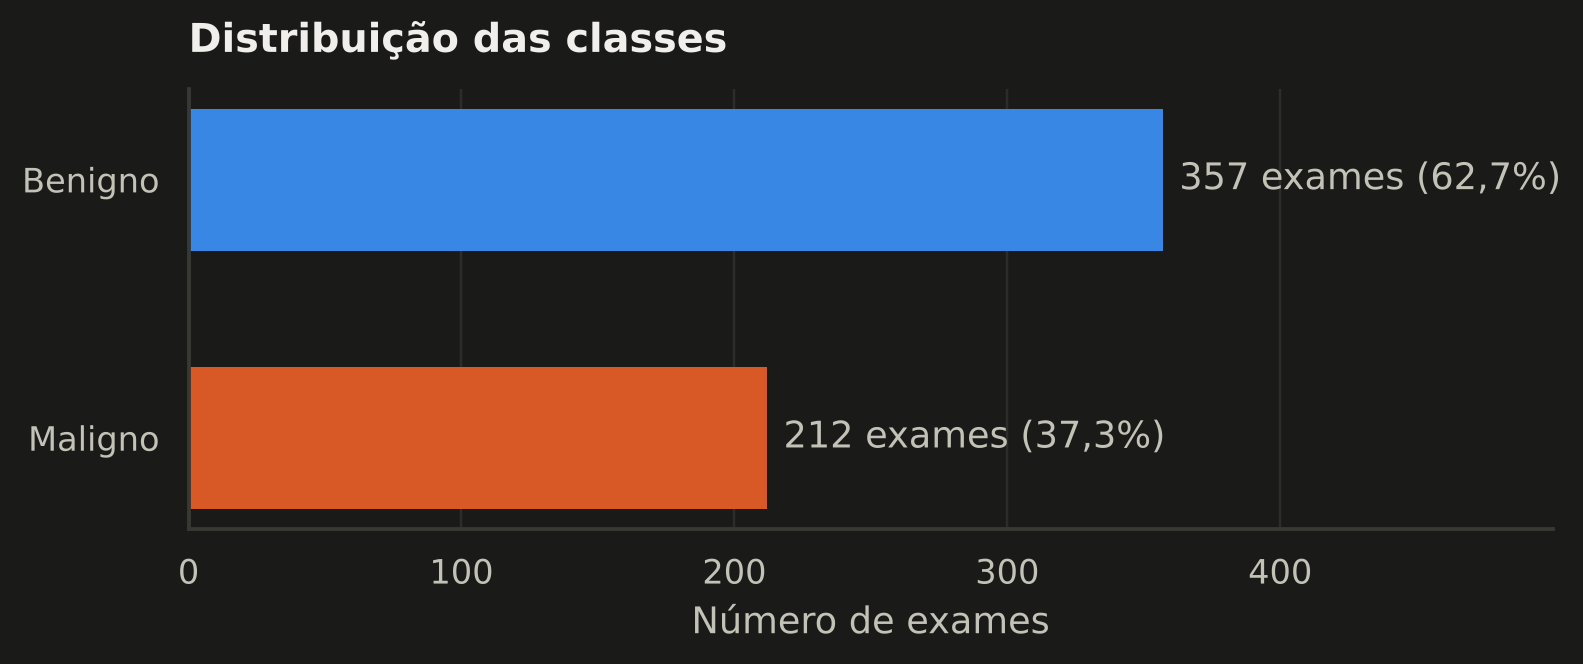

In [6]:
contagem = df_cancer["diagnostico"].map(dict(enumerate(NOMES_CLASSES))).value_counts()
proporcao = contagem / contagem.sum()
display(pd.DataFrame({"registros": contagem, "proporção": proporcao.round(3)}))

fig, ax = plt.subplots(figsize=(8, 2.6))
barras = ax.barh(contagem.index, contagem.values, height=0.55,
                 color=[COR_CLASSE[c] for c in contagem.index])
for barra, n, p in zip(barras, contagem.values, proporcao.values):
    ax.text(barra.get_width() + 6, barra.get_y() + barra.get_height() / 2,
            f"{n} exames ({br(100 * p)}%)", va="center", color=CORES["texto_2"])
ax.set_xlim(0, contagem.max() * 1.4)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Número de exames")
ax.set_title("Distribuição das classes")
plt.show()

São 357 benignos (62,7%) e 212 malignos (37,3%). O desbalanceamento é moderado, não extremo, e tem duas consequências práticas:

1. Um "modelo" que responde sempre *benigno* já acerta 62,7% dos casos. Essa é a acurácia mínima para um modelo ser levado a sério, e também o motivo de olhar recall e precision além da acurácia.
2. Na divisão treino/teste vou usar **estratificação**, para manter essa mesma proporção nos dois conjuntos.

**Estatísticas descritivas**

In [7]:
# Uma linha por atributo (tabela transposta) para ficar mais fácil de ler
df_cancer.drop(columns="diagnostico").describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.000,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.000,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.000,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.000,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.000,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.000,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.000,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.000,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.000,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.000,0.063,0.007,0.050,0.058,0.062,0.066,0.097


O que mais chama atenção é a **diferença de escala** entre os atributos. `mean area` vai de 143,5 a 2.501, enquanto `mean smoothness` fica entre 0,05 e 0,16. Para modelos que dependem de distância (KNN) ou de regularização (Regressão Logística), isso faz diferença: sem padronização, os atributos com números grandes dominariam os outros. Essa é a justificativa para o `StandardScaler` no pré-processamento.

Para ver quais atributos separam melhor as classes, calculo a correlação de cada um com o diagnóstico e comparo as médias de cada grupo.

In [8]:
corr_alvo = df_cancer.corr()["diagnostico"].drop("diagnostico").sort_values(ascending=False)

comparacao_medias = (df_cancer.groupby("diagnostico").mean().T
                     .rename(columns=dict(enumerate(NOMES_CLASSES))))
comparacao_medias["razão maligno/benigno"] = comparacao_medias["Maligno"] / comparacao_medias["Benigno"]
comparacao_medias["correlação com diagnóstico"] = corr_alvo

print("5 atributos mais e 5 menos relacionados ao diagnóstico:")
pd.concat([comparacao_medias.loc[corr_alvo.index[:5]], comparacao_medias.loc[corr_alvo.index[-5:]]])

5 atributos mais e 5 menos relacionados ao diagnóstico:


diagnostico,Benigno,Maligno,razão maligno/benigno,correlação com diagnóstico
worst concave points,0.074,0.182,2.448,0.794
worst perimeter,87.006,141.370,1.625,0.783
mean concave points,0.026,0.088,3.421,0.777
worst radius,13.380,21.135,1.580,0.776
mean perimeter,78.075,115.365,1.478,0.743
fractal dimension error,0.004,0.004,1.117,0.078
symmetry error,0.021,0.020,0.995,-0.007
texture error,1.220,1.211,0.992,-0.008
mean fractal dimension,0.063,0.063,0.997,-0.013
smoothness error,0.007,0.007,0.942,-0.067


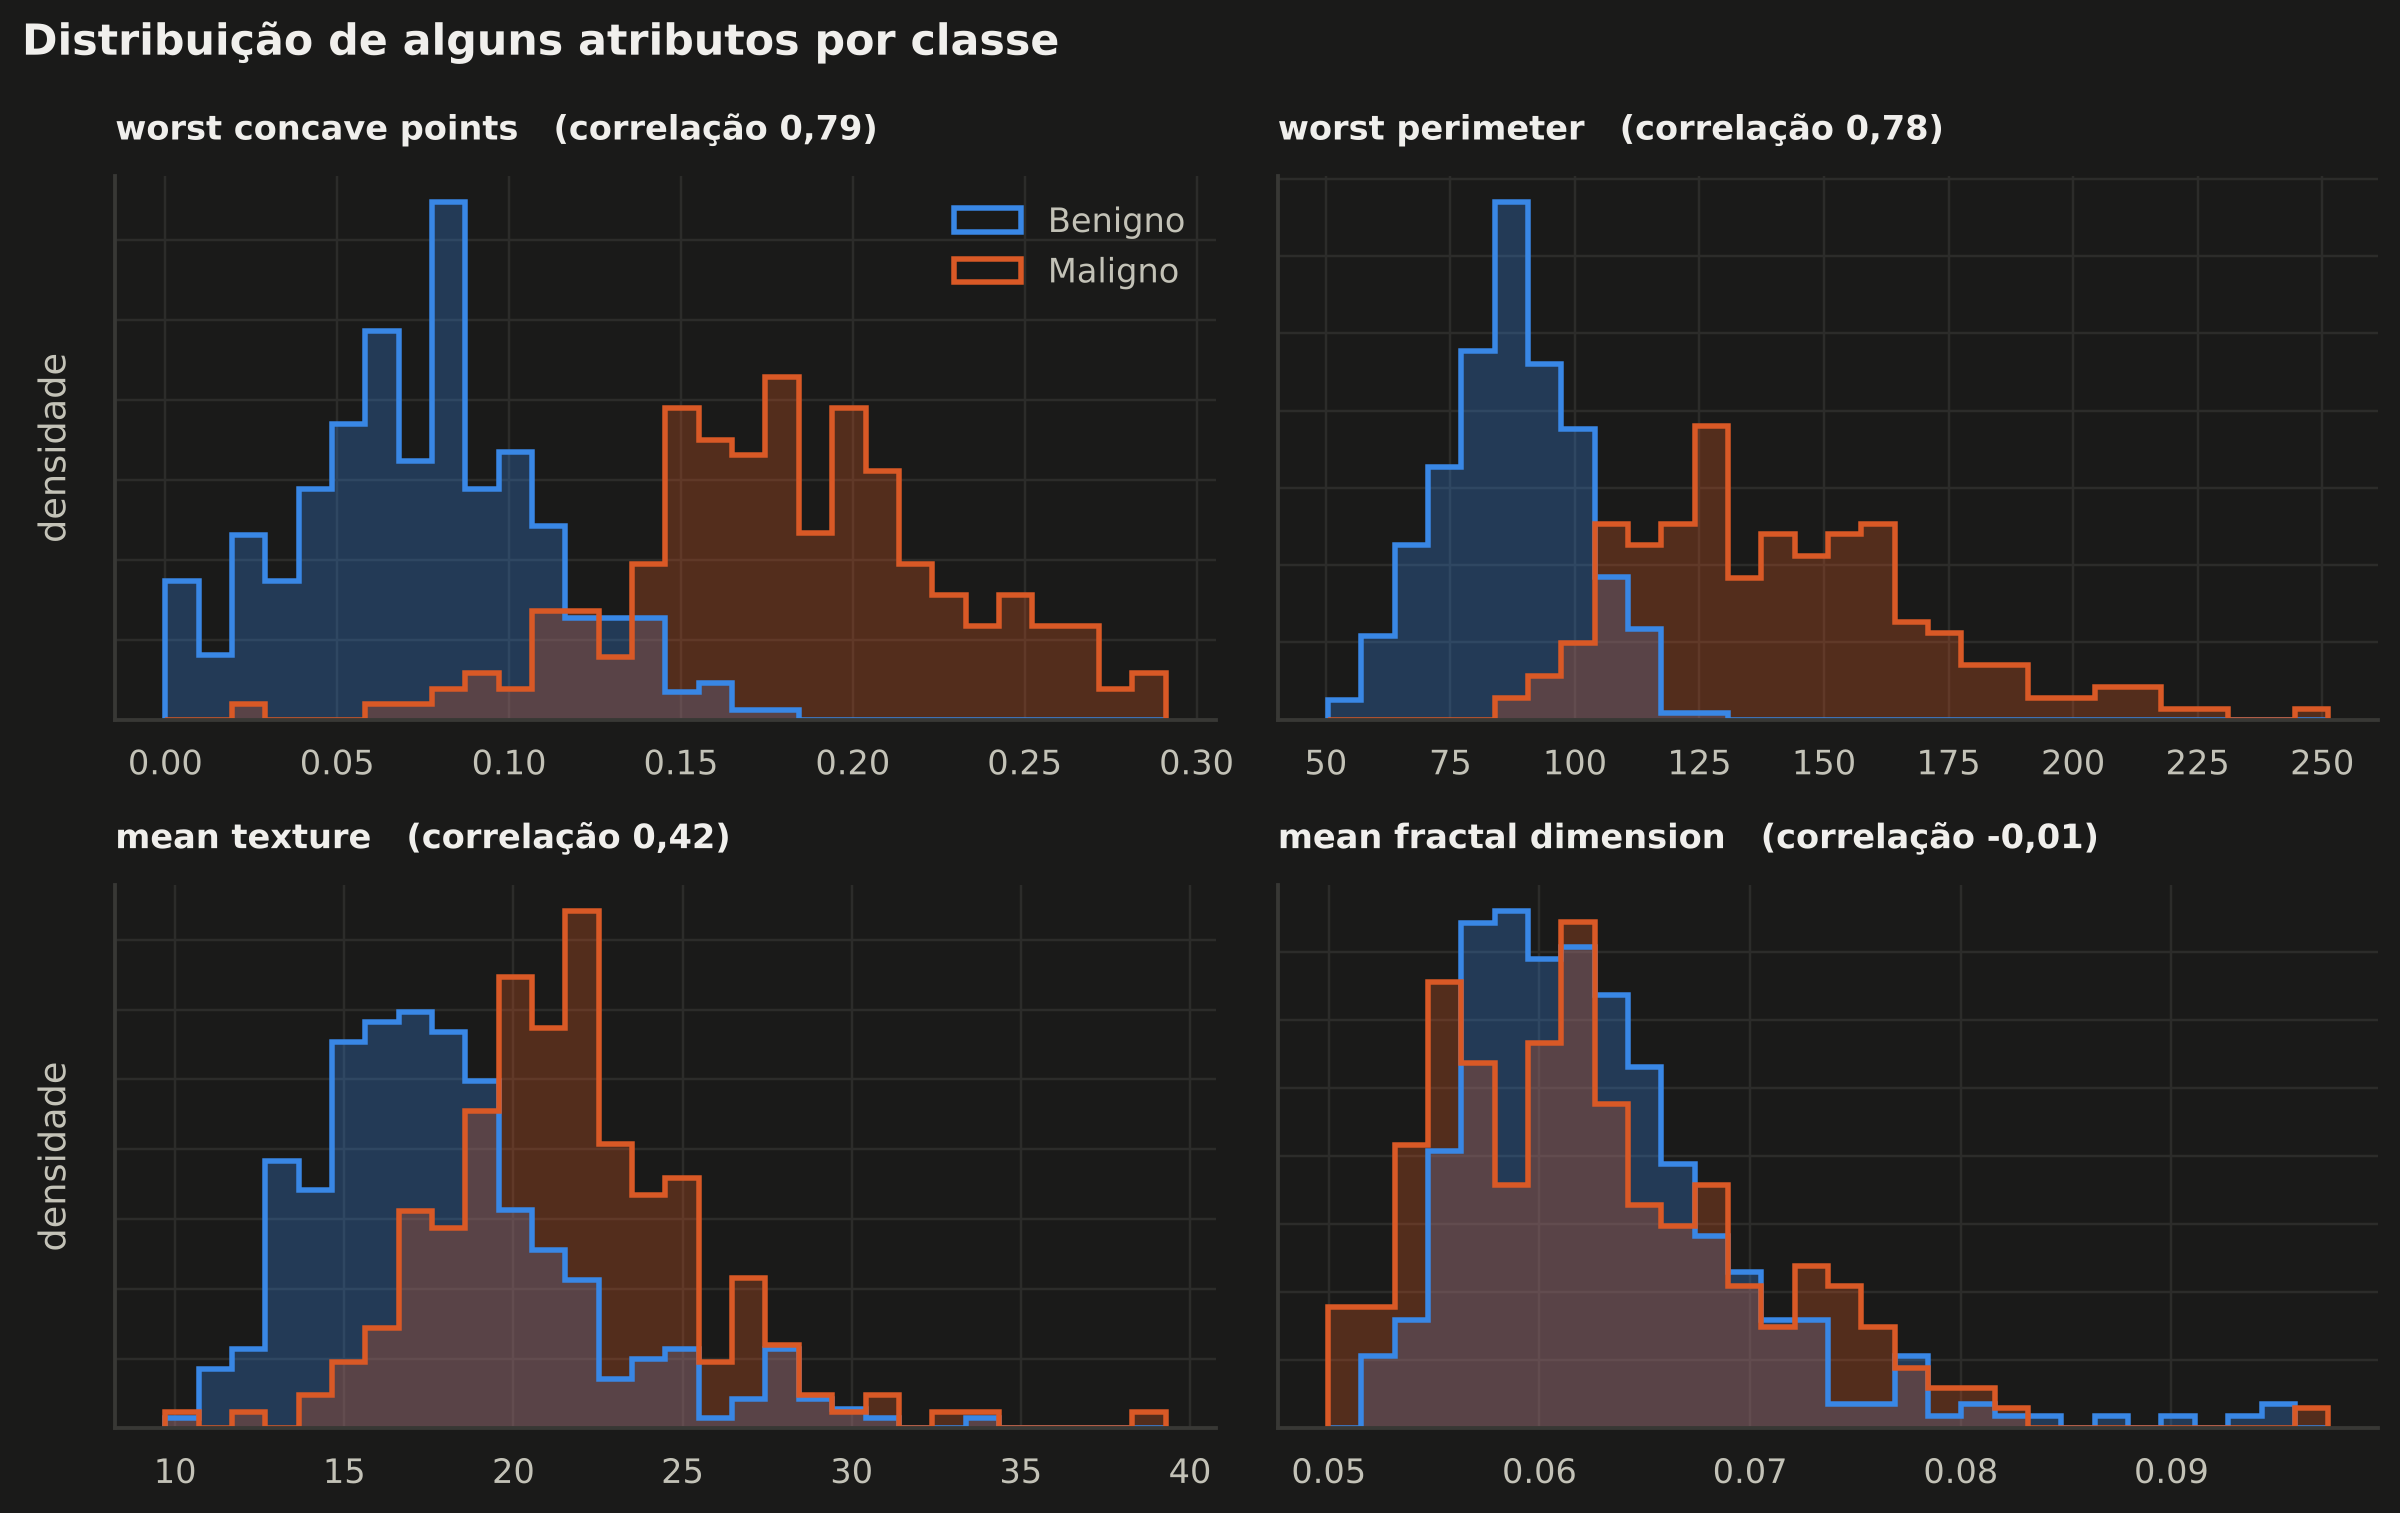

In [9]:
# Distribuição de quatro atributos em cada classe: dois que separam bem, um intermediário e um quase inútil
exemplos = ["worst concave points", "worst perimeter", "mean texture", "mean fractal dimension"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, coluna in zip(axes.flat, exemplos):
    faixas = np.histogram_bin_edges(df_cancer[coluna], bins=30)  # mesmas faixas para as duas classes
    for codigo, nome in enumerate(NOMES_CLASSES):
        valores = df_cancer.loc[df_cancer["diagnostico"] == codigo, coluna]
        ax.hist(valores, bins=faixas, density=True, histtype="stepfilled", alpha=0.3, color=COR_CLASSE[nome])
        ax.hist(valores, bins=faixas, density=True, histtype="step", linewidth=1.8,
                color=COR_CLASSE[nome], label=nome)
    ax.set_title(f"{coluna}   (correlação {br(corr_alvo[coluna], 2)})", fontsize=11)
    ax.set_yticklabels([])
for ax in axes[:, 0]:
    ax.set_ylabel("densidade")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Distribuição de alguns atributos por classe", x=0.01, ha="left",
             fontsize=14, fontweight="bold", color=CORES["texto"])
fig.tight_layout()
plt.show()

Os gráficos confirmam a tabela. Em `worst concave points` e `worst perimeter` as duas classes quase não se sobrepõem: tumores malignos têm células maiores e com contornos mais irregulares. `mean texture` ajuda, mas tem bastante sobreposição. Já `mean fractal dimension` praticamente não distingue as classes. Como vários atributos já separam bem os grupos sozinhos, a expectativa é que até um modelo linear vá bem aqui.

**Correlação entre os atributos.** Olhando só os 10 atributos do tipo `mean`, para o mapa não ficar ilegível:

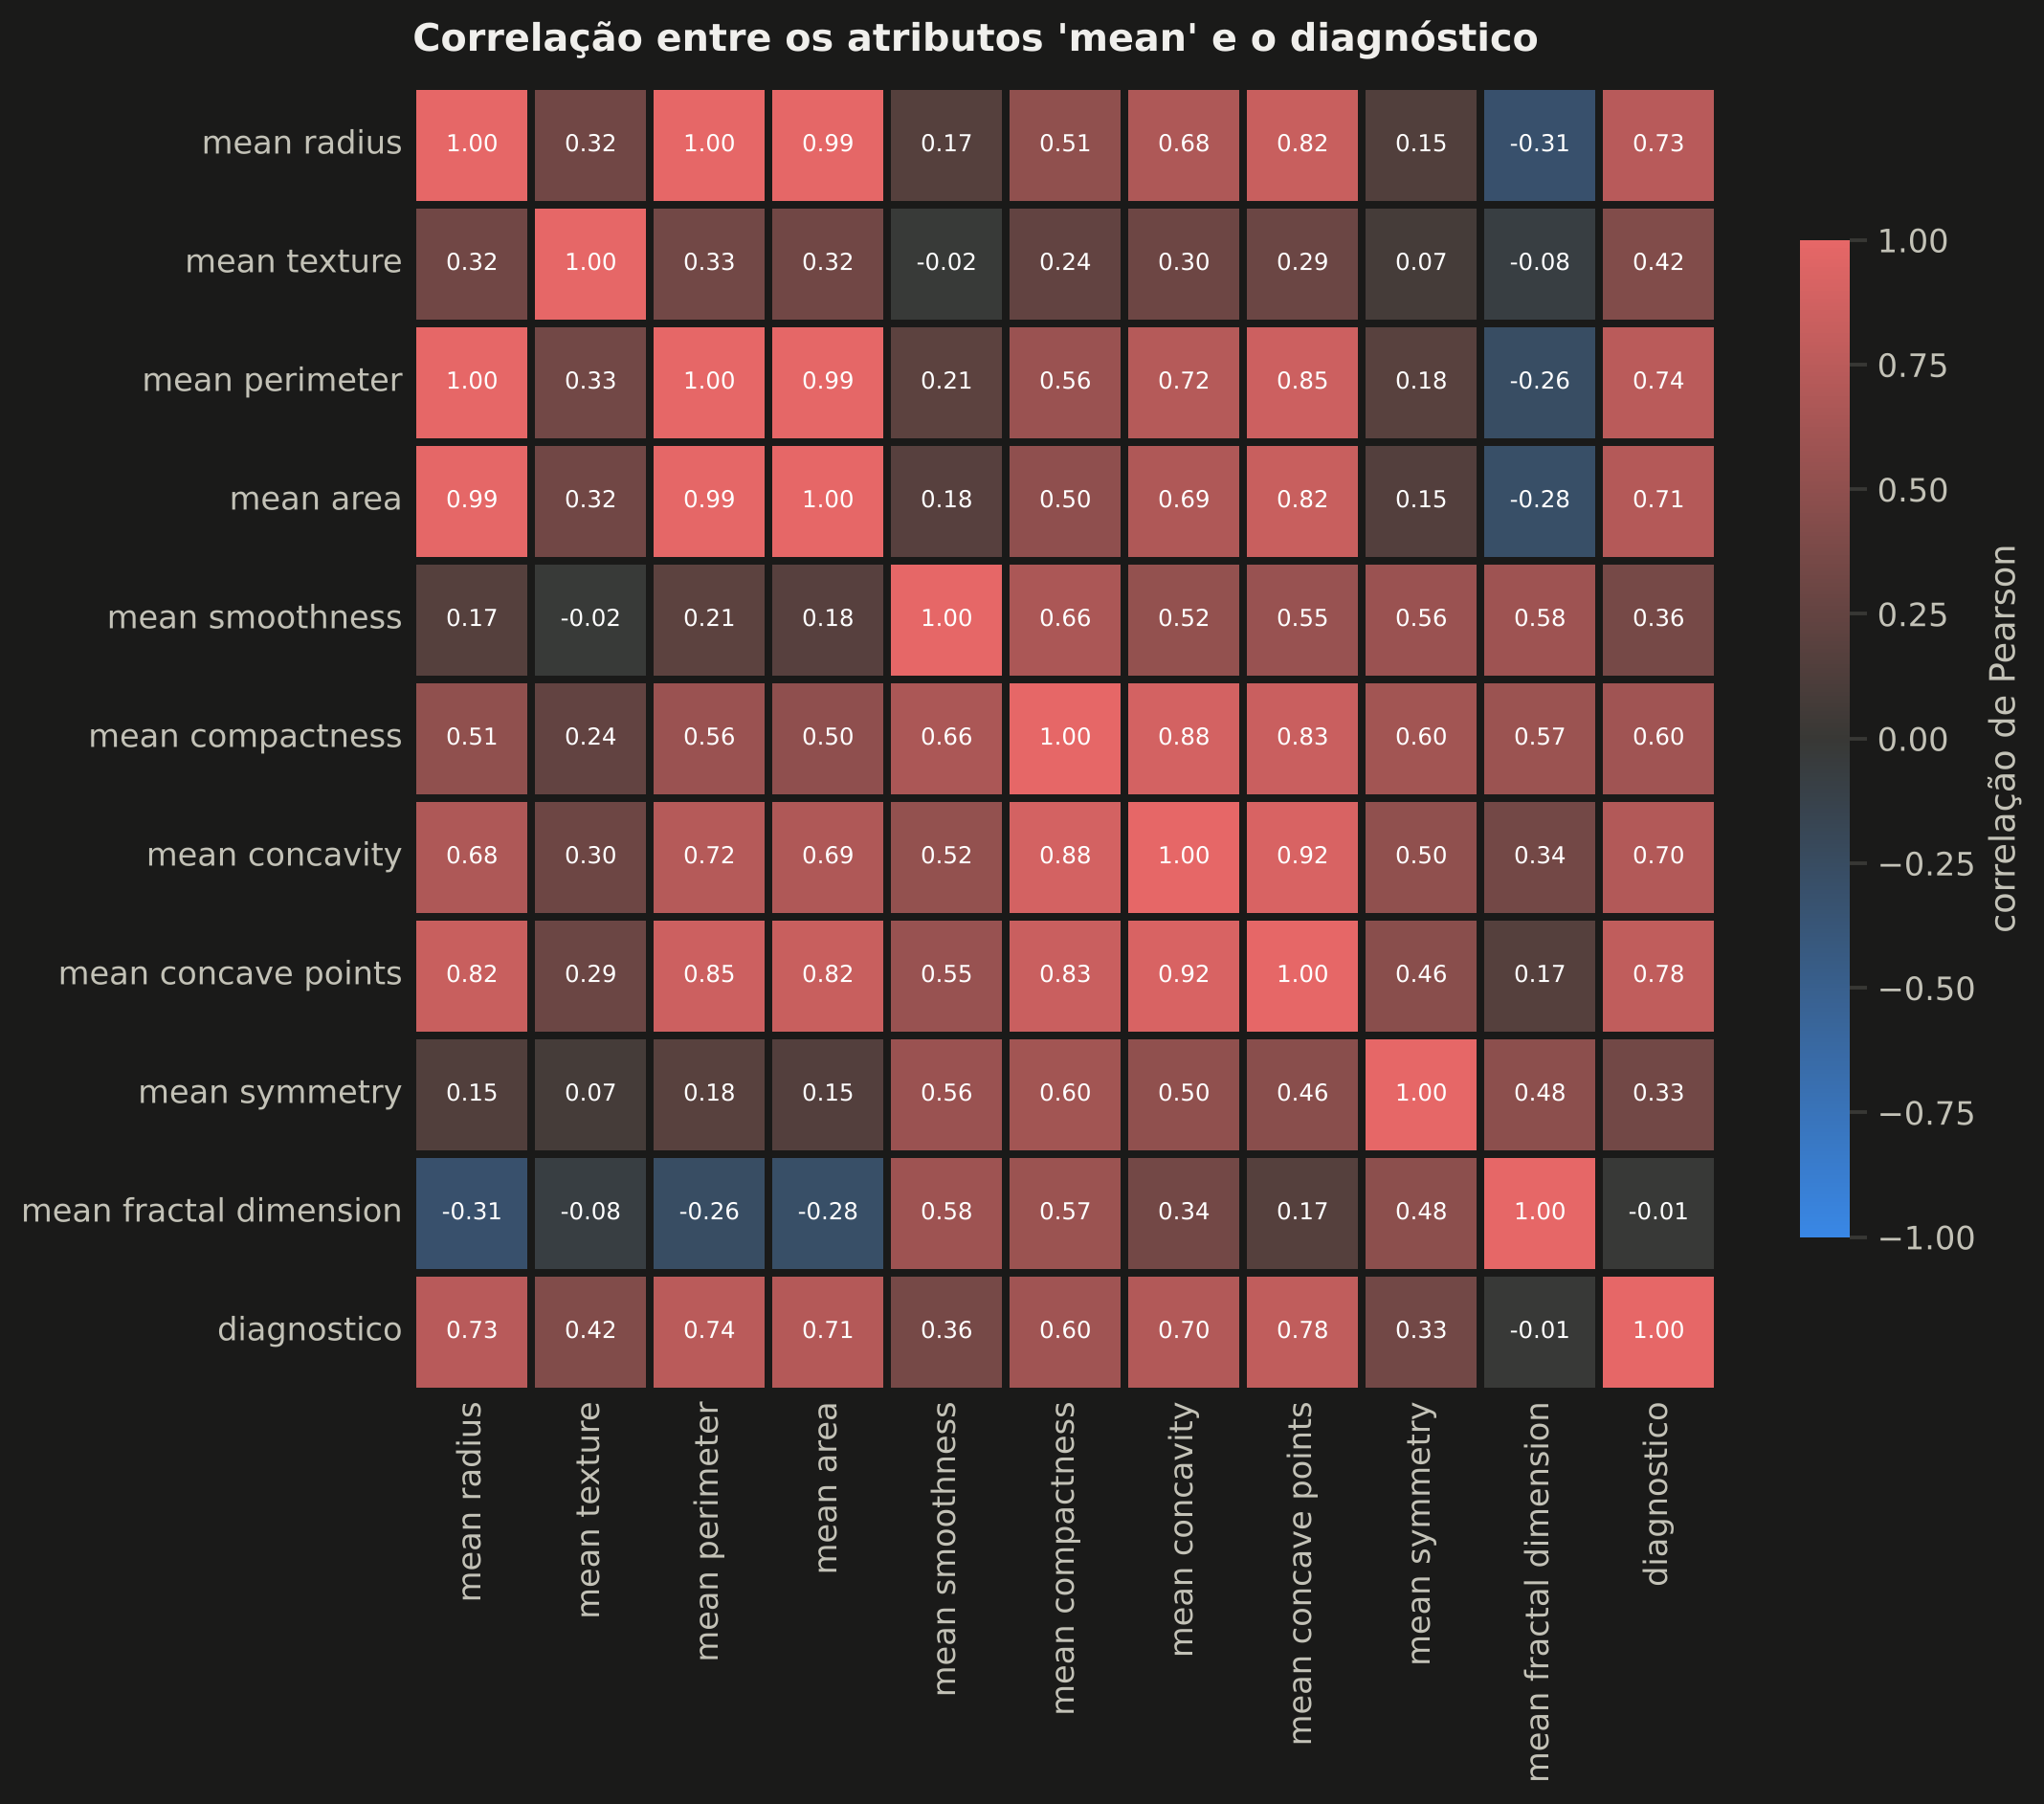

In [10]:
colunas_mean = [c for c in df_cancer.columns if c.startswith("mean ")] + ["diagnostico"]
matriz_corr = df_cancer[colunas_mean].corr()

fig, ax = plt.subplots(figsize=(10, 8.2))
sns.heatmap(matriz_corr, cmap=CMAP_DIV, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=2, linecolor=CORES["fundo"], square=True,
            cbar_kws={"shrink": 0.75, "label": "correlação de Pearson"}, ax=ax)
estilizar_colorbar(ax.collections[0].colorbar)
ax.grid(False)
ax.tick_params(length=0)
ax.set_title("Correlação entre os atributos 'mean' e o diagnóstico")
plt.show()

`mean radius`, `mean perimeter` e `mean area` têm correlação de praticamente 1 entre si. Faz sentido, porque perímetro e área são calculados a partir do raio. Ou seja, há bastante **informação redundante** (multicolinearidade). Isso não atrapalha a previsão, mas significa que não dá para interpretar o peso de cada atributo isoladamente no modelo linear. Também significa que, se fosse preciso simplificar, daria para remover vários atributos sem perder muito.

### 4.2 Parte 2: California Housing

In [11]:
print(f"Registros (regiões): {df_casas.shape[0]}")
print(f"Colunas:             {df_casas.shape[1]} (8 atributos + o alvo MedHouseVal)")
print(f"Valores ausentes:    {df_casas.isna().sum().sum()}")
print(f"Linhas duplicadas:   {df_casas.duplicated().sum()}")
df_casas.describe().T

Registros (regiões): 20640
Colunas:             9 (8 atributos + o alvo MedHouseVal)
Valores ausentes:    0
Linhas duplicadas:   0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.000,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.000,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.000,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.000,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.000,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.000,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.000,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.000,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.000,2.069,1.154,0.150,1.196,1.797,2.647,5.000


São 20.640 regiões, 8 atributos numéricos, sem valores ausentes nem duplicatas. A tabela já levanta três pontos importantes:

- **O alvo tem teto.** O valor máximo é 5,00001, ou seja, US$ 500 mil. No censo, valores acima disso foram registrados como "US$ 500 mil ou mais". O valor real dessas regiões é desconhecido; só se sabe que é pelo menos esse. `HouseAge` (máximo 52) e `MedInc` (máximo 15,0001) também parecem cortados no limite.
- **Há valores extremos.** `AveRooms` chega a 141,9 cômodos por domicílio e `AveOccup` a 1.243 moradores por domicílio, sendo que 75% das regiões ficam abaixo de 6,1 e 3,3, respectivamente. Provavelmente são regiões com poucos domicílios e muitas casas vazias (de veraneio, por exemplo) ou com alojamentos coletivos.
- **As escalas são muito diferentes:** `Population` está na casa dos milhares, e `AveBedrms` perto de 1.

In [12]:
TETO = df_casas["MedHouseVal"].max()
n_teto = (df_casas["MedHouseVal"] == TETO).sum()
print(f"Regiões no teto de {TETO} (US$ 500 mil ou mais): {n_teto} ({br(100 * n_teto / len(df_casas))}%)")
print(f"Regiões com HouseAge = 52 (máximo): {(df_casas['HouseAge'] == 52).sum()}")

for coluna in ["AveRooms", "AveBedrms", "AveOccup", "Population"]:
    q99 = df_casas[coluna].quantile(0.99)
    print(f"{coluna:>10}: 99% das regiões até {q99:8.2f} | máximo {df_casas[coluna].max():9.2f}")

Regiões no teto de 5.00001 (US$ 500 mil ou mais): 965 (4,7%)
Regiões com HouseAge = 52 (máximo): 1273
  AveRooms: 99% das regiões até    10.36 | máximo    141.91
 AveBedrms: 99% das regiões até     2.13 | máximo     34.07
  AveOccup: 99% das regiões até     5.39 | máximo   1243.33
Population: 99% das regiões até  5805.83 | máximo  35682.00


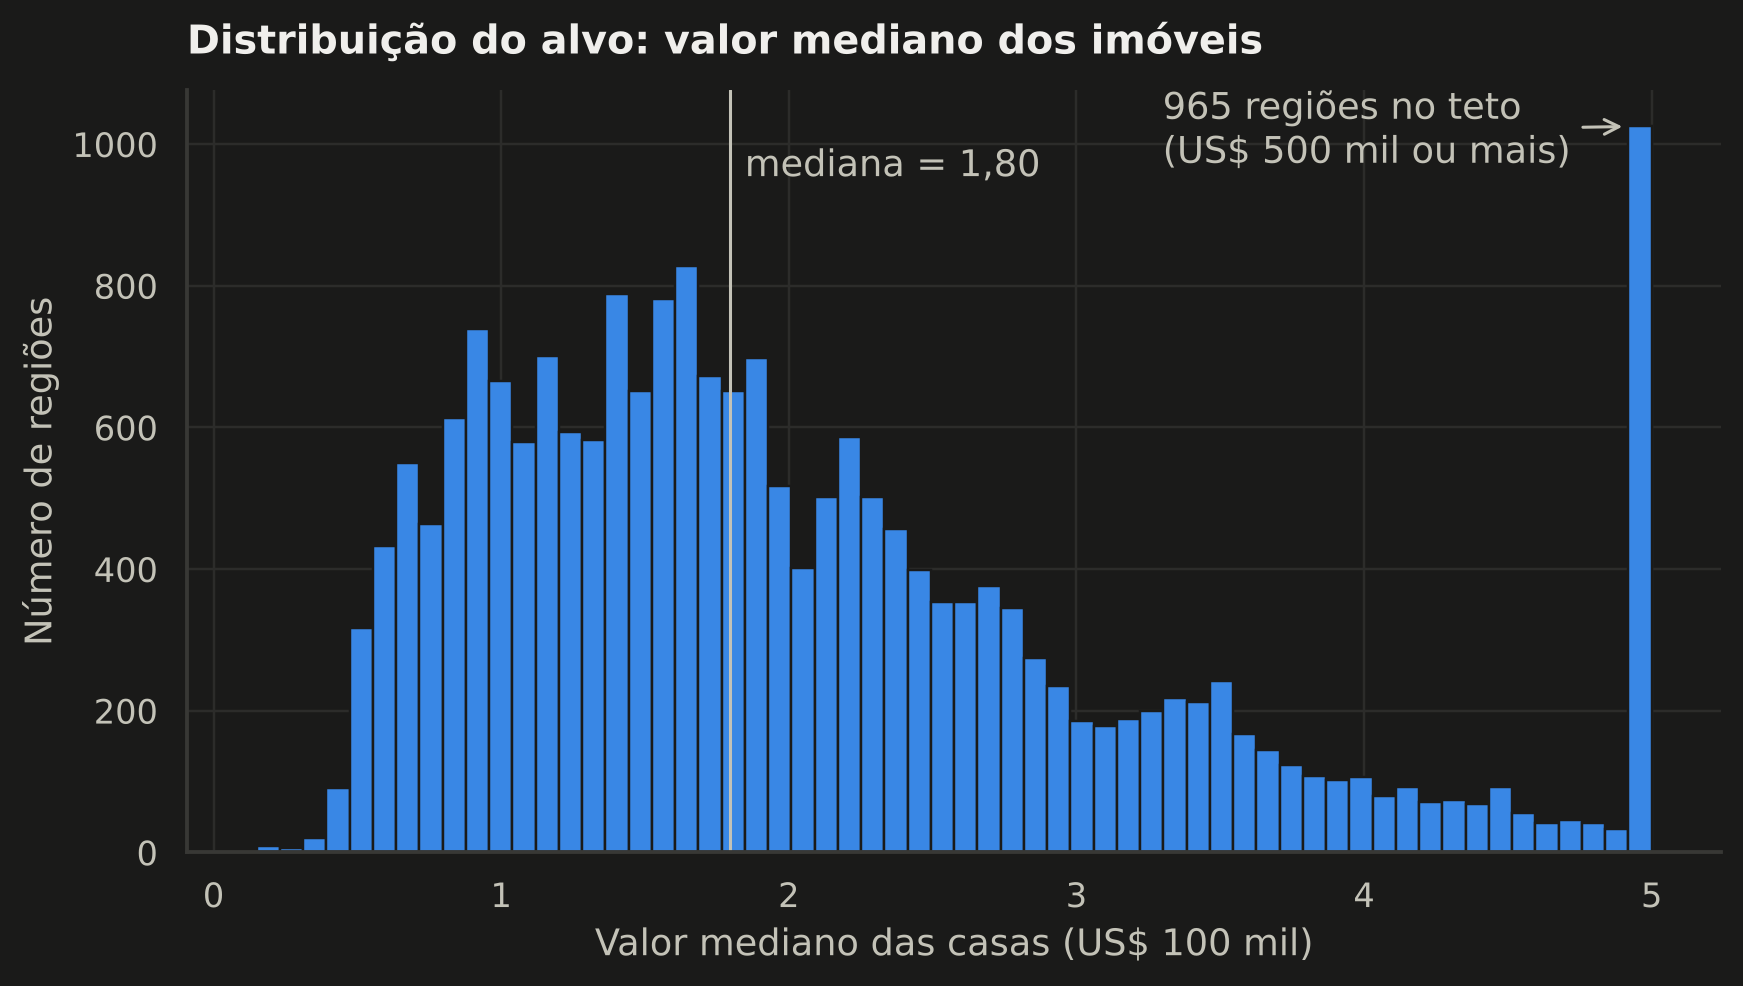

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
alturas, faixas, _ = ax.hist(df_casas["MedHouseVal"], bins=60, color=CORES["azul"],
                             edgecolor=CORES["fundo"], linewidth=0.8)
ax.annotate(f"{n_teto} regiões no teto\n(US$ 500 mil ou mais)",
            xy=(faixas[-2], alturas[-1]), xytext=(3.3, alturas[-1] * 0.95),
            color=CORES["texto_2"], arrowprops=dict(arrowstyle="->", color=CORES["texto_2"]))
ax.axvline(df_casas["MedHouseVal"].median(), color=CORES["texto_2"], linewidth=1)
ax.text(df_casas["MedHouseVal"].median() + 0.05, alturas.max() * 0.97,
        f"mediana = {br(df_casas['MedHouseVal'].median(), 2)}", color=CORES["texto_2"], va="top")
ax.set_xlabel("Valor mediano das casas (US$ 100 mil)")
ax.set_ylabel("Número de regiões")
ax.set_title("Distribuição do alvo: valor mediano dos imóveis")
plt.show()

A distribuição é assimétrica à direita: metade das regiões vale entre US$ 120 mil e US$ 265 mil, e a mediana fica em cerca de US$ 180 mil. A barra isolada no final é o teto: são 965 regiões (4,7%) "empilhadas" artificialmente em 5,0. Para a Regressão Linear isso é um problema. O valor real dessas regiões é desconhecido (só se sabe que é de pelo menos 5), então tanto o treino quanto a avaliação ficam distorcidos nesse trecho.

**Onde ficam as regiões mais caras?** Como o dataset tem latitude e longitude, dá para desenhar o mapa da Califórnia usando os próprios dados:

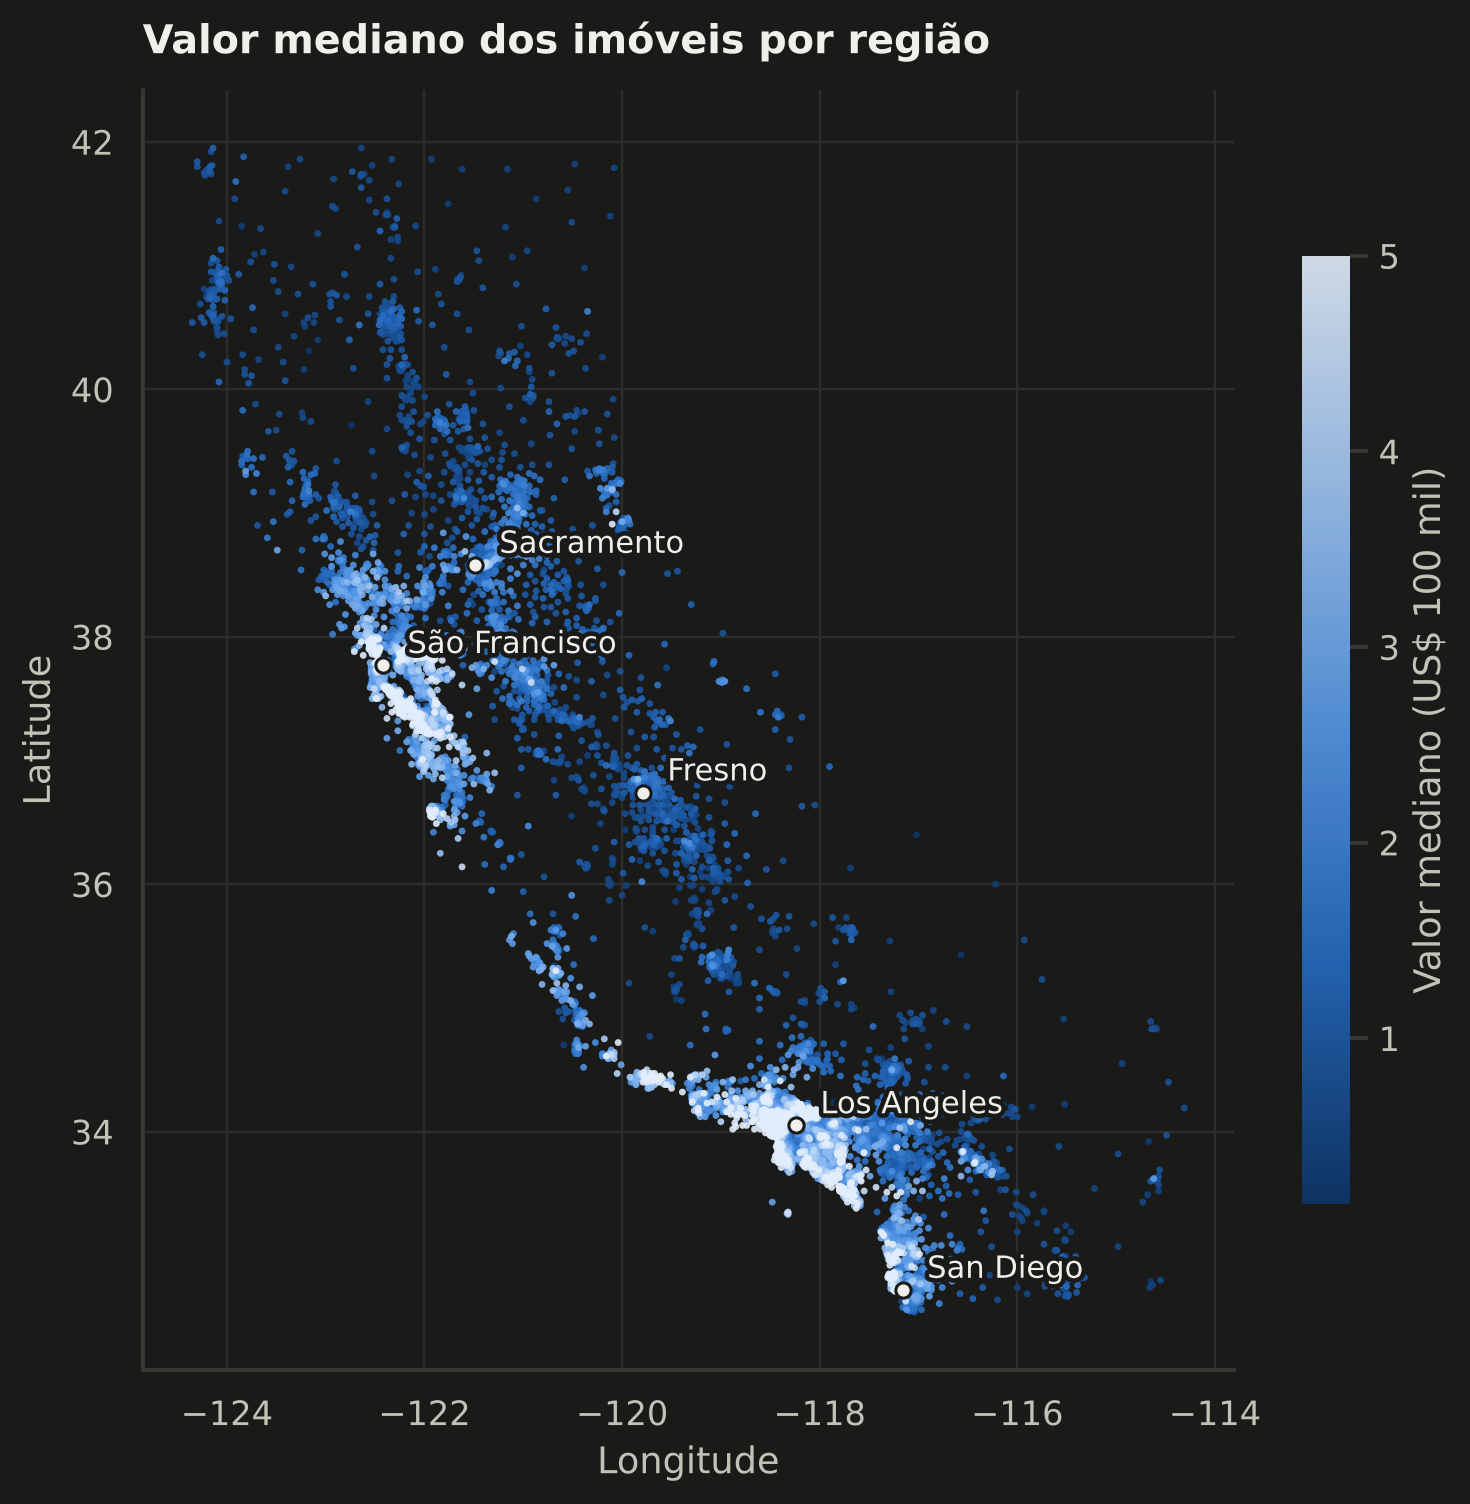

In [14]:
cidades = {"São Francisco": (-122.42, 37.77), "Sacramento": (-121.49, 38.58), "Fresno": (-119.79, 36.74),
           "Los Angeles": (-118.24, 34.05), "San Diego": (-117.16, 32.72)}

fig, ax = plt.subplots(figsize=(8, 8))
ordem = df_casas.sort_values("MedHouseVal")  # as regiões mais caras são desenhadas por cima
pontos = ax.scatter(ordem["Longitude"], ordem["Latitude"], c=ordem["MedHouseVal"], cmap=CMAP_SEQ,
                    s=5, alpha=0.9, linewidths=0)
for nome, (lon, lat) in cidades.items():
    ax.plot(lon, lat, "o", markersize=5, color=CORES["texto"], markeredgecolor=CORES["fundo"])
    ax.annotate(nome, (lon, lat), xytext=(8, 4), textcoords="offset points",
                color=CORES["texto"], fontsize=10, path_effects=CONTORNO)
ax.set_aspect(1 / np.cos(np.radians(37)))  # corrige a distorção de usar graus como se fossem distância
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Valor mediano dos imóveis por região")
estilizar_colorbar(fig.colorbar(pontos, ax=ax, shrink=0.7, label="Valor mediano (US$ 100 mil)"))
plt.show()

O mapa mostra a característica mais importante deste problema: **localização**. As regiões caras (pontos claros) ficam no litoral, principalmente na região de São Francisco e entre Los Angeles e San Diego. O interior (Vale Central, deserto) é bem mais barato. Essa relação não é linear: o preço não sobe nem desce de forma constante quando se anda para o norte ou para o leste. Ele depende de estar perto da costa e das grandes cidades. Isso vai aparecer nos resultados da Regressão Linear.

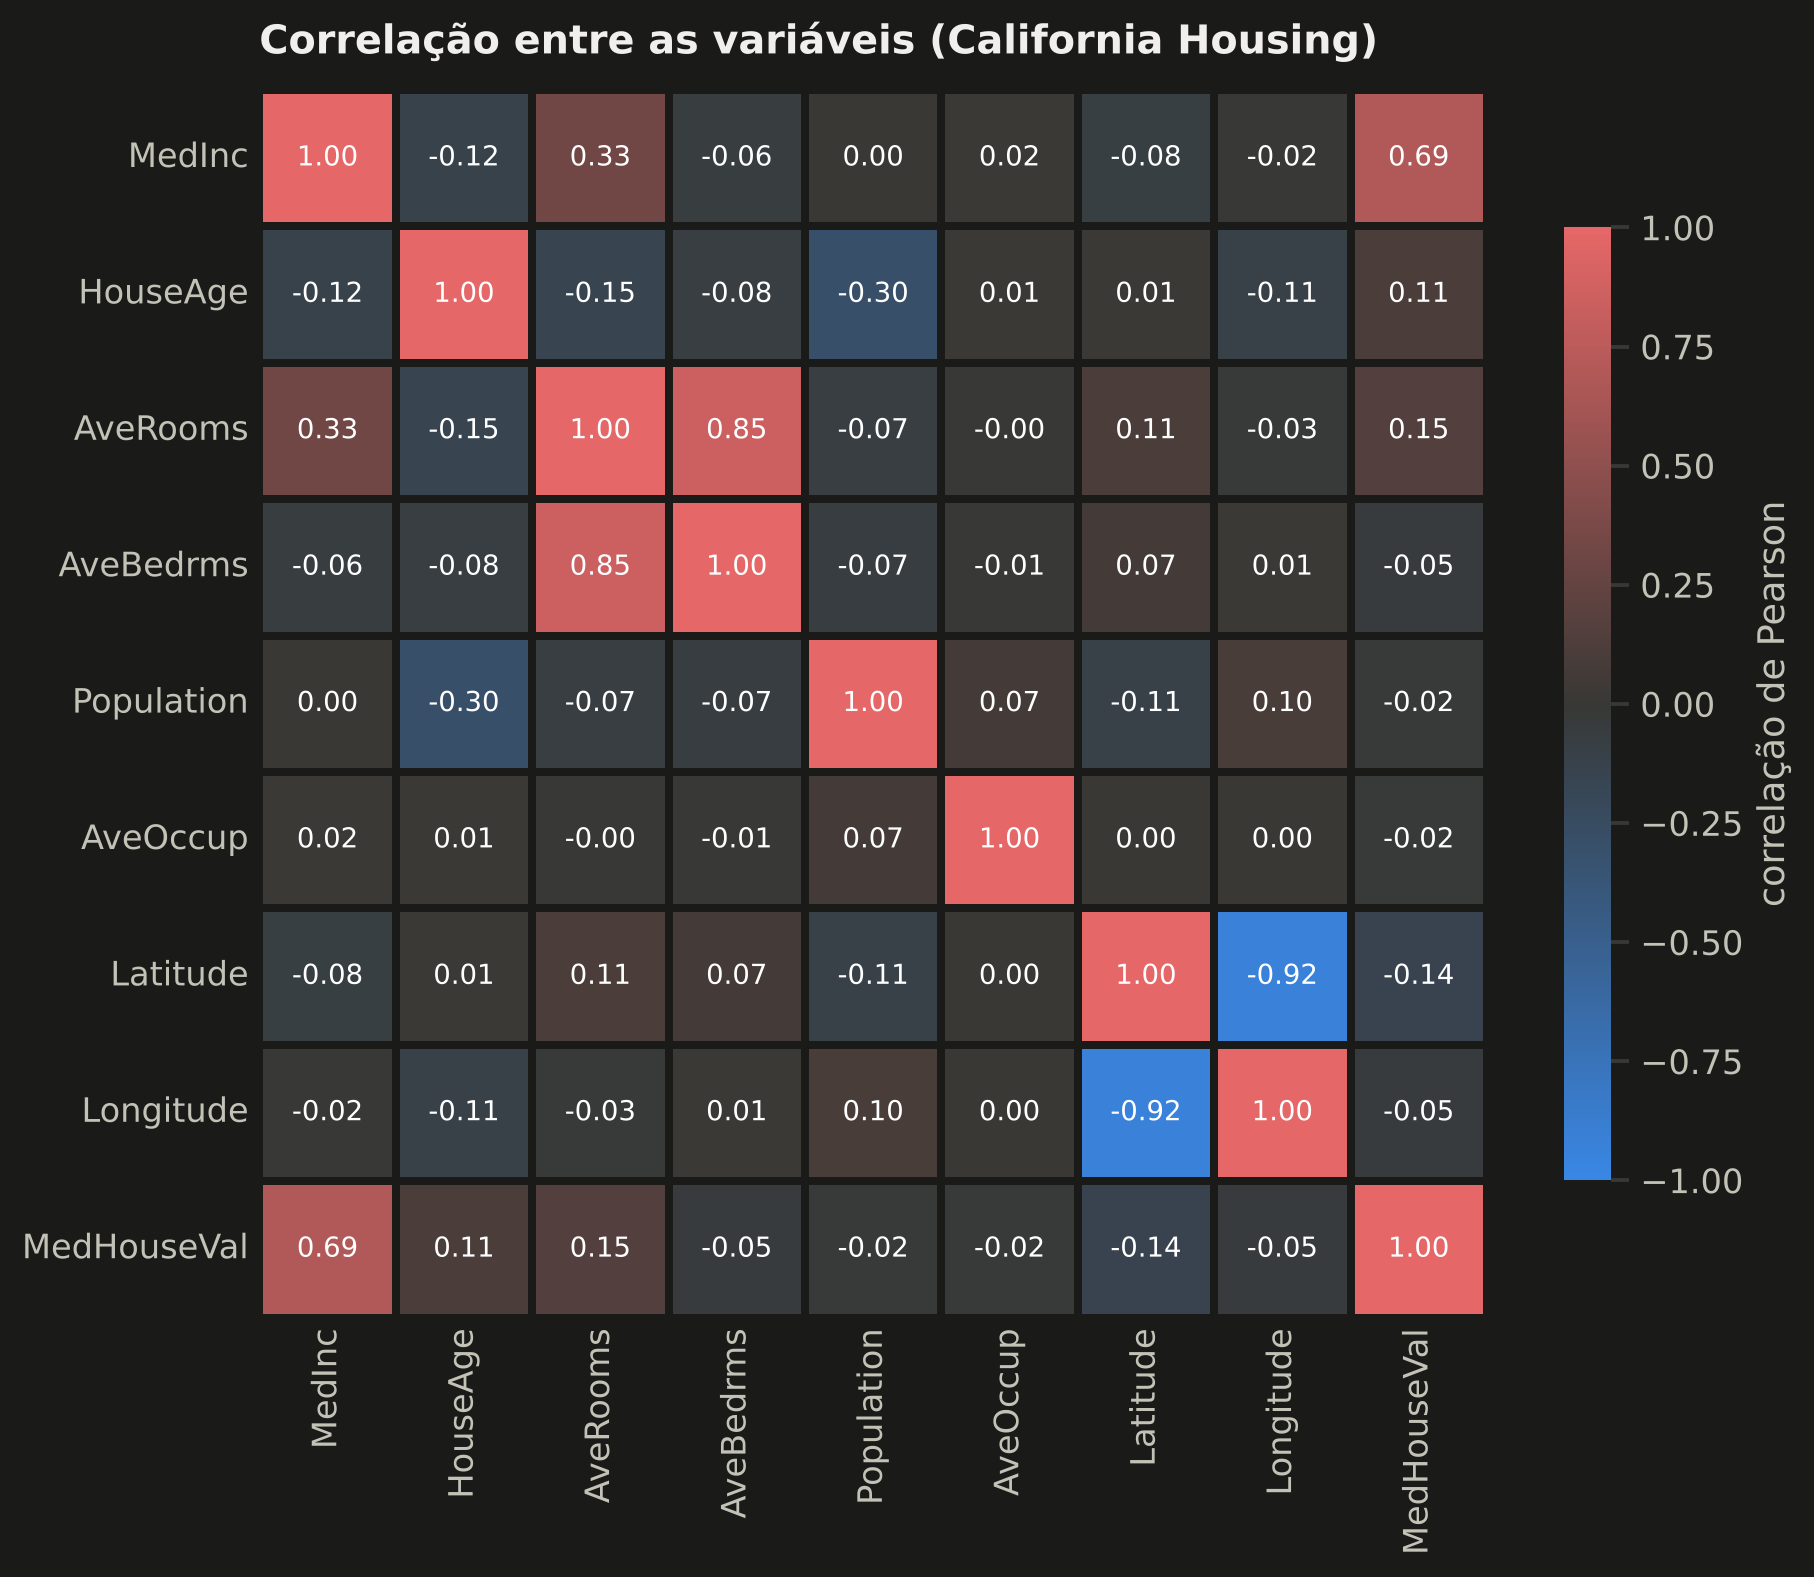

In [15]:
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(df_casas.corr(), cmap=CMAP_DIV, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 9}, linewidths=2, linecolor=CORES["fundo"], square=True,
            cbar_kws={"shrink": 0.75, "label": "correlação de Pearson"}, ax=ax)
estilizar_colorbar(ax.collections[0].colorbar)
ax.grid(False)
ax.tick_params(length=0)
ax.set_title("Correlação entre as variáveis (California Housing)")
plt.show()

- **`MedInc` é de longe a variável mais ligada ao preço** (correlação de 0,69). As outras, sozinhas, têm correlação fraca com o alvo.
- `Latitude` e `Longitude` têm correlação fraca com o preço, mas isso não quer dizer que a localização não importe (o mapa mostra o contrário). A correlação de Pearson só mede relação **linear**, e a relação com a localização não é linear.
- `AveRooms` e `AveBedrms` têm correlação de 0,85 entre si (casas com mais cômodos têm mais quartos). `Latitude` e `Longitude` têm −0,92, por causa do formato diagonal do estado. Isso vai complicar a interpretação dos coeficientes.

Como `MedInc` é a variável principal, vale ver a relação dela com o preço de perto:

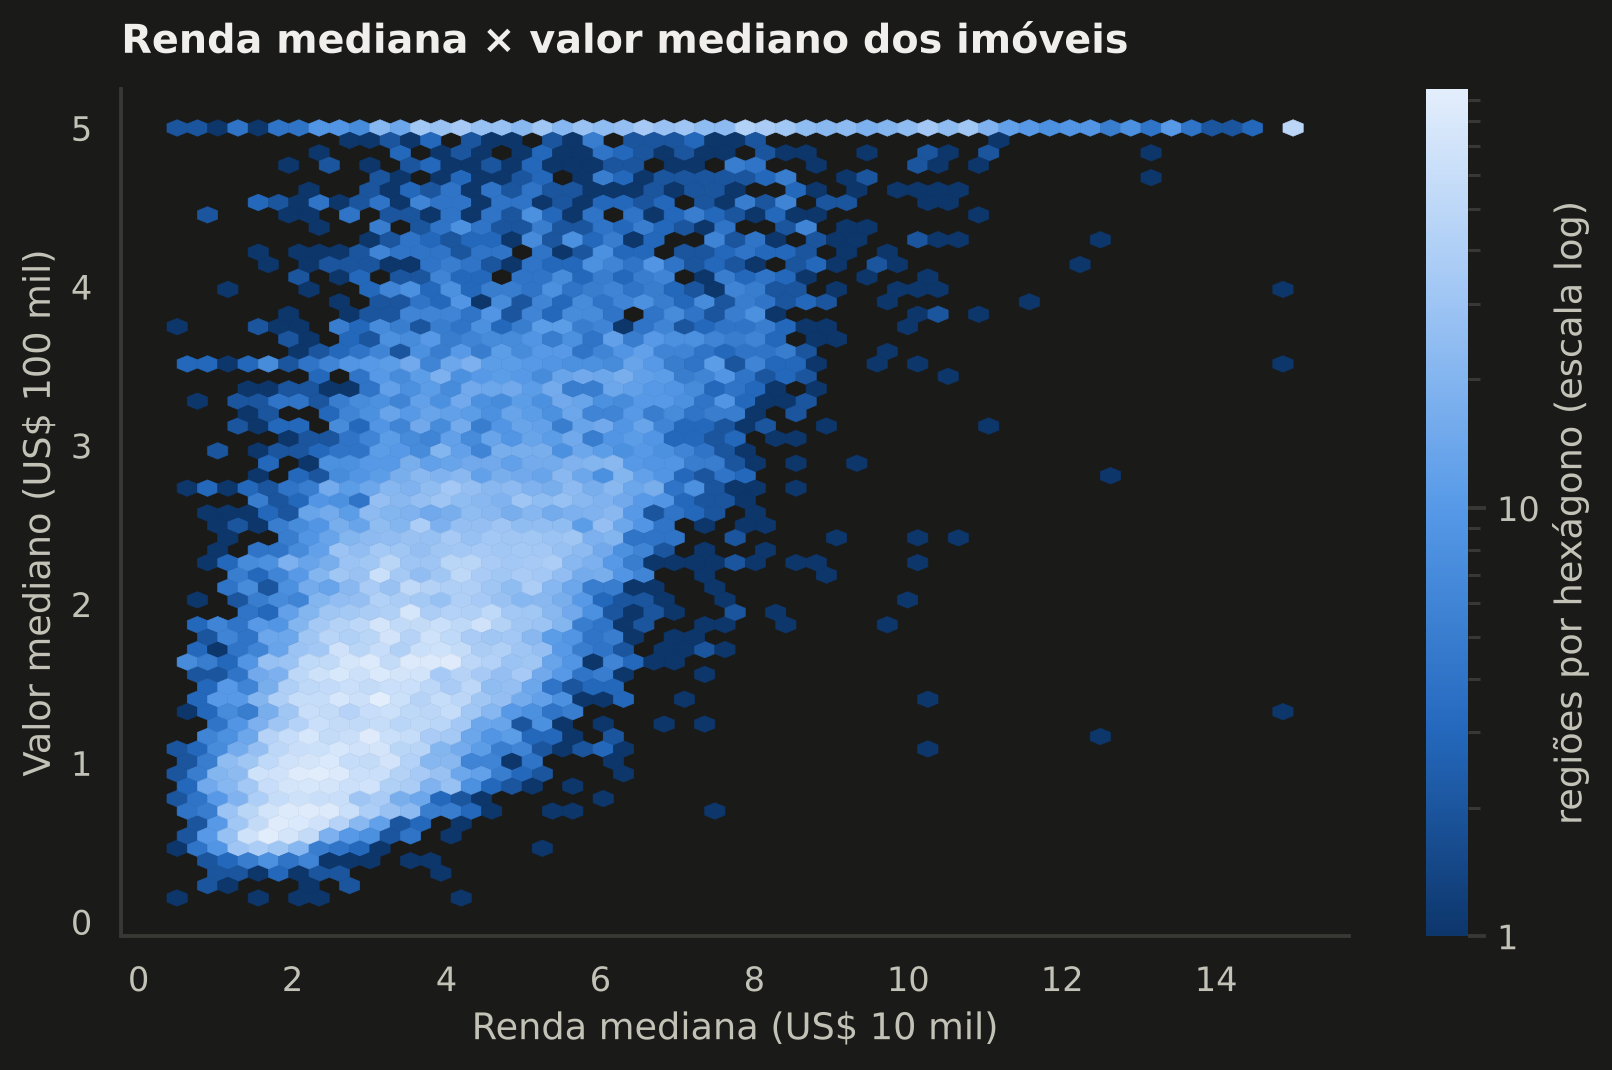

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
hexagonos = ax.hexbin(df_casas["MedInc"], df_casas["MedHouseVal"], gridsize=55, cmap=CMAP_SEQ,
                      mincnt=1, bins="log", edgecolors="face", linewidths=0.2)
ax.set_xlabel("Renda mediana (US$ 10 mil)")
ax.set_ylabel("Valor mediano (US$ 100 mil)")
ax.set_title("Renda mediana × valor mediano dos imóveis")
ax.grid(False)
estilizar_colorbar(fig.colorbar(hexagonos, ax=ax, label="regiões por hexágono (escala log)"),
                   numeros_simples=True)
plt.show()

A tendência é claramente crescente, mas a dispersão é grande: com a mesma renda, há regiões baratas e caras, e o que explica isso é principalmente a localização. A linha horizontal no topo é o teto de US$ 500 mil, que "achata" justamente as regiões de renda alta.

## 5. Pré-processamento

### 5.1 Parte 1: separação de X e y e divisão treino/teste

- **X** (variáveis independentes): os 30 atributos dos exames.
- **y** (variável alvo): `diagnostico` (0 = benigno, 1 = maligno).

A divisão é **80% treino e 20% teste**, estratificada pela classe. O conjunto de teste fica guardado e só é usado na avaliação final. A escolha do modelo é feita com validação cruzada apenas sobre o treino.

Não há dados ausentes nem variáveis categóricas, então o único tratamento necessário é a **padronização** (média 0 e desvio 1). Ela fica dentro de um `Pipeline` junto com o modelo. Assim, a média e o desvio são calculados só com os dados de treino (e, na validação cruzada, só com os dados de treino de cada *fold*). Isso evita vazamento de informação do teste para o treino.

In [17]:
X_cancer = df_cancer.drop(columns="diagnostico")
y_cancer = df_cancer["diagnostico"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.2, stratify=y_cancer, random_state=SEED)

print(f"X: {X_cancer.shape} | y: {y_cancer.shape}")
print(f"Treino: {X_train_c.shape[0]} exames ({y_train_c.mean():.1%} malignos)")
print(f"Teste:  {X_test_c.shape[0]} exames ({y_test_c.mean():.1%} malignos)")

X: (569, 30) | y: (569,)
Treino: 455 exames (37.4% malignos)
Teste:  114 exames (36.8% malignos)


A proporção de malignos ficou praticamente igual no treino e no teste (cerca de 37%), como esperado com a estratificação.

### 5.2 Parte 2: separação de X e y e divisão treino/teste

- **y** (variável dependente): `MedHouseVal`, o valor mediano dos imóveis.
- **X** (variáveis independentes): as outras 8 colunas.

Mesma divisão 80/20. Aqui não há estratificação, porque o alvo é contínuo.

Duas decisões que tomei aqui:

1. **Manter os valores extremos e as regiões no teto.** Removê-los deixaria as métricas mais bonitas, mas de forma artificial: essas regiões existem e o modelo teria que lidar com elas se fosse usado de verdade. Prefiro manter os dados como estão e mostrar na avaliação o efeito que eles têm.
2. **Padronizar os atributos.** Na Regressão Linear comum, padronizar não muda as previsões. O benefício é colocar todos os coeficientes na mesma escala ("efeito de aumentar 1 desvio padrão"), o que permite comparar o peso de cada variável.

In [18]:
X_casas = df_casas.drop(columns="MedHouseVal")
y_casas = df_casas["MedHouseVal"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_casas, y_casas, test_size=0.2, random_state=SEED)

print(f"X: {X_casas.shape} | y: {y_casas.shape}")
print(f"Treino: {X_train_r.shape[0]} regiões | Teste: {X_test_r.shape[0]} regiões")
print(f"Valor médio do alvo - treino: {y_train_r.mean():.3f} | teste: {y_test_r.mean():.3f}")

X: (20640, 8) | y: (20640,)
Treino: 16512 regiões | Teste: 4128 regiões
Valor médio do alvo - treino: 2.072 | teste: 2.055


## 6. Treinamento dos modelos

### 6.1 Parte 1: comparação dos algoritmos e escolha do modelo

O enunciado pede um dos quatro algoritmos. Antes de escolher, comparei os quatro com **validação cruzada estratificada de 5 *folds*** usando só os dados de treino. Em cada rodada, o modelo treina com 4/5 do treino e é avaliado no 1/5 restante. A média e o desvio dessas 5 rodadas dão uma ideia mais confiável do desempenho do que uma única divisão.

Os hiperparâmetros são os padrões do scikit-learn, com dois ajustes: `max_iter` maior na Regressão Logística, para garantir a convergência, e 300 árvores no Random Forest.

In [19]:
modelos = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "KNN (k = 5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = ["accuracy", "precision", "recall", "f1"]  # precision/recall/F1 da classe maligno (1)

resultados_cv = {}
for nome, modelo in modelos.items():
    res = cross_validate(modelo, X_train_c, y_train_c, cv=cv_cls, scoring=metricas_cv)
    resultados_cv[nome] = {m: res[f"test_{m}"] for m in metricas_cv}

# Tabela "média ± desvio" ordenada pelo F1
tabela_cv = pd.DataFrame({
    nome: {m: f"{v.mean():.3f} ± {v.std():.3f}" for m, v in r.items()}
    for nome, r in resultados_cv.items()
}).T
tabela_cv = tabela_cv.loc[sorted(resultados_cv, key=lambda n: -resultados_cv[n]["f1"].mean())]
tabela_cv.columns = ["Accuracy", "Precision", "Recall", "F1-Score"]
tabela_cv

,Accuracy,Precision,Recall,F1-Score
Regressão Logística,0.974 ± 0.015,0.977 ± 0.028,0.953 ± 0.040,0.964 ± 0.021
KNN (k = 5),0.965 ± 0.019,0.988 ± 0.025,0.918 ± 0.034,0.951 ± 0.026
Random Forest,0.960 ± 0.016,0.958 ± 0.022,0.935 ± 0.039,0.946 ± 0.023
Árvore de Decisão,0.923 ± 0.033,0.900 ± 0.041,0.894 ± 0.061,0.896 ± 0.045


A **Regressão Logística** teve a melhor média em acurácia (~0,974), recall (~0,953) e F1 (~0,964). O KNN teve a maior precision (~0,988), mas encontrou menos malignos (recall ~0,918). O Random Forest ficou perto dos dois. A Árvore de Decisão sozinha foi a pior: cerca de 5 pontos percentuais a menos de acurácia, 7 de F1, e mais variação entre os *folds*. Esse resultado é coerente com a exploração: as classes já são quase separáveis por uma combinação linear dos atributos, então um modelo linear simples basta. A árvore única, por outro lado, tende a decorar detalhes do treino.

Vale ser honesto: entre Regressão Logística, Random Forest e KNN, a diferença é menor que um desvio padrão. Com tão poucos dados, não dá para afirmar que um é melhor que o outro. Escolhi a **Regressão Logística** pelo melhor recall e F1 médios e por ser mais simples e interpretável. Ela também devolve probabilidades bem comportadas, que vou usar para ajustar o limiar de decisão na seção 7. A escolha foi feita **antes** de olhar o conjunto de teste, e não vou mudá-la depois de ver o resultado.

In [20]:
modelo_cls = modelos["Regressão Logística"]
modelo_cls.fit(X_train_c, y_train_c)

# Atributos com maior peso (coeficientes sobre dados padronizados)
coef_cls = pd.Series(modelo_cls[-1].coef_[0], index=X_cancer.columns)
print("Atributos com mais peso na Regressão Logística (positivo = puxa para 'maligno'):")
coef_cls.reindex(coef_cls.abs().sort_values(ascending=False).index).head(8).round(3)

Atributos com mais peso na Regressão Logística (positivo = puxa para 'maligno'):


worst texture          1.434
radius error           1.233
worst symmetry         1.061
mean concave points    0.953
worst concavity        0.911
area error             0.909
compactness error     -0.907
worst area             0.900
dtype: float64

Os coeficientes com mais peso são de textura, concavidade e tamanho (`worst texture`, `radius error`, `mean concave points`, `worst area`...), o que bate com a análise exploratória. Como os atributos são muito correlacionados entre si, esses pesos devem ser lidos como uma indicação geral, não como "o efeito" de cada atributo isolado.

### 6.2 Parte 2: Regressão Linear

O modelo é uma `LinearRegression` (mínimos quadrados) com padronização antes. Para ter uma referência, treinei também um *baseline* que sempre prevê a média do treino. Qualquer modelo útil precisa ser bem melhor que ele.

In [21]:
modelo_reg = make_pipeline(StandardScaler(), LinearRegression())
modelo_reg.fit(X_train_r, y_train_r)

baseline = DummyRegressor(strategy="mean").fit(X_train_r, y_train_r)

# Estabilidade: R² em validação cruzada de 5 folds dentro do treino
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
r2_cv = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                        X_train_r, y_train_r, cv=cv_reg, scoring="r2")
print("R² em cada fold:", np.round(r2_cv, 3))
print(f"R² médio na validação cruzada: {r2_cv.mean():.3f} ± {r2_cv.std():.3f}")
print(f"R² no próprio treino:          {r2_score(y_train_r, modelo_reg.predict(X_train_r)):.3f}")

R² em cada fold: [0.61  0.604 0.635 0.601 0.607]
R² médio na validação cruzada: 0.611 ± 0.012
R² no próprio treino:          0.613


O R² ficou entre 0,60 e 0,64 em todos os *folds*, e o R² no próprio treino é parecido (0,613). Ou seja, o modelo **não está decorando os dados** (não há sobreajuste). O limite aqui é outro: o modelo é simples demais para a relação real entre as variáveis.

Coeficientes do modelo (sobre dados padronizados, ou seja, o quanto o valor previsto muda, em US$ 100 mil, quando o atributo aumenta 1 desvio padrão e os outros ficam fixos):

,coeficiente (padronizado),1 desvio padrão do atributo,efeito em US$ por desvio
Latitude,-0.897,2.137,-89700
Longitude,-0.870,2.006,-87000
AveRooms,-0.294,2.387,-29400
AveOccup,-0.041,11.579,-4100
Population,-0.002,1137.056,-200
HouseAge,0.123,12.602,12300
AveBedrms,0.339,0.433,33900
MedInc,0.854,1.904,85400


Intercepto: 2.072 (= valor médio do alvo no treino, já que X está padronizado)


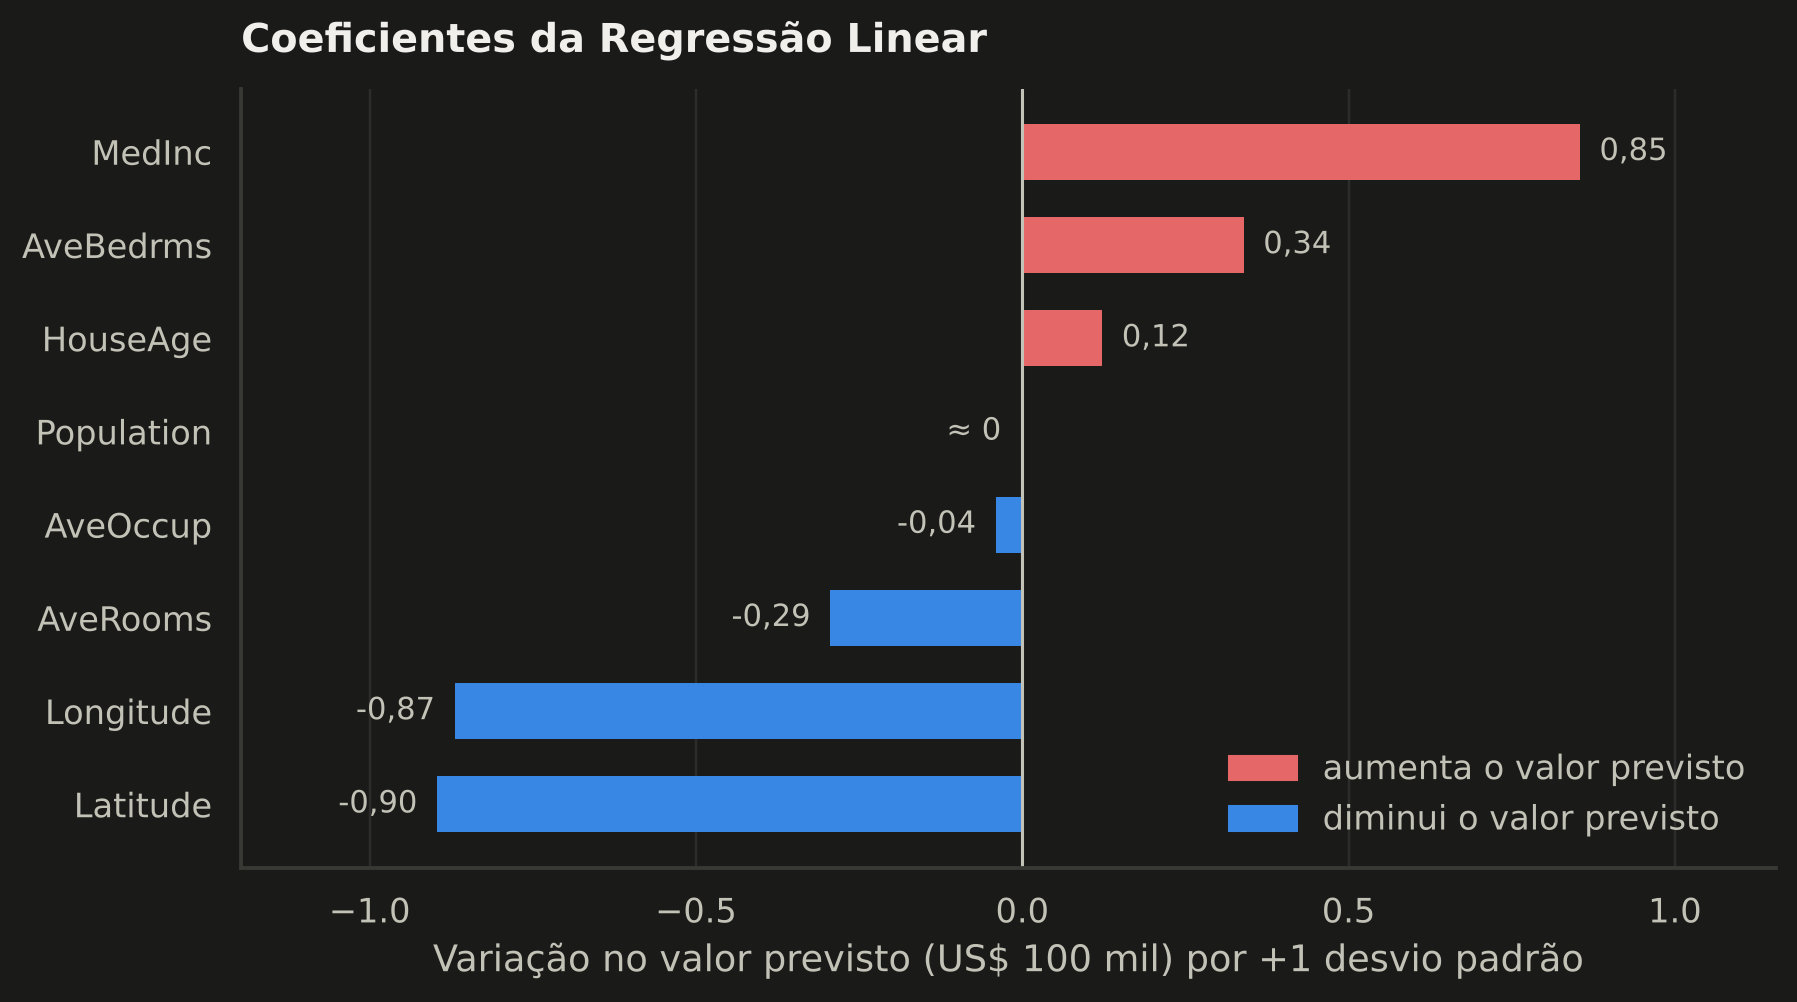

In [22]:
coef_reg = pd.Series(modelo_reg[-1].coef_, index=X_casas.columns).sort_values()
desvios = X_train_r.std()

display(pd.DataFrame({
    "coeficiente (padronizado)": coef_reg,
    "1 desvio padrão do atributo": desvios[coef_reg.index],
    "efeito em US$ por desvio": (coef_reg * 100_000).round(-2).astype(int),
}))
print(f"Intercepto: {modelo_reg[-1].intercept_:.3f} (= valor médio do alvo no treino, já que X está padronizado)")

fig, ax = plt.subplots(figsize=(9, 4.6))
cores_barras = [CORES["vermelho"] if c > 0 else CORES["azul"] for c in coef_reg]
ax.barh(coef_reg.index, coef_reg.values, color=cores_barras, height=0.6)
ax.axvline(0, color=CORES["texto_2"], linewidth=1)
for i, valor in enumerate(coef_reg.values):
    rotulo = "≈ 0" if abs(valor) < 0.005 else br(valor, 2)
    ax.text(valor + (0.03 if valor >= 0 else -0.03), i, rotulo, va="center",
            ha="left" if valor >= 0 else "right", color=CORES["texto_2"], fontsize=10)
ax.set_xlim(coef_reg.min() - 0.3, coef_reg.max() + 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Variação no valor previsto (US$ 100 mil) por +1 desvio padrão")
ax.set_title("Coeficientes da Regressão Linear")
ax.legend(handles=[mpl.patches.Patch(color=CORES["vermelho"], label="aumenta o valor previsto"),
                   mpl.patches.Patch(color=CORES["azul"], label="diminui o valor previsto")],
          loc="lower right")
plt.show()

Como ler os coeficientes:

- **`MedInc` (+0,85):** um aumento de 1 desvio padrão na renda mediana (cerca de US$ 19 mil a mais por família) eleva o valor previsto em uns US$ 85 mil, mantendo o resto igual. Bate com a correlação de 0,69 vista antes.
- **`Latitude` (−0,90) e `Longitude` (−0,87):** os dois negativos dizem que o valor cai indo para o norte e para o leste. Juntos, eles aproximam o efeito "perto do litoral sul é mais caro". Um modelo linear só consegue representar isso como um plano inclinado sobre o mapa. Ele não consegue modelar "caro perto de São Francisco **e** perto de Los Angeles, mais barato no meio".
- **`AveRooms` (−0,29) e `AveBedrms` (+0,34):** os sinais parecem estranhos (mais cômodos diminuiria o preço?). Isso acontece porque as duas variáveis têm correlação de 0,85 entre si, e o modelo divide o efeito entre elas de forma instável. É um exemplo clássico de que, com multicolinearidade, **não se deve interpretar cada coeficiente isoladamente**.
- `Population` e `AveOccup` quase não têm efeito.

## 7. Avaliação dos resultados

### 7.1 Parte 1: métricas no conjunto de teste

Agora sim uso os 114 exames de teste, que o modelo nunca viu. A classe positiva é **maligno**, então:

- **Accuracy:** fração de exames classificados corretamente.
- **Precision:** dos exames que o modelo chamou de malignos, quantos realmente eram.
- **Recall (sensibilidade):** dos tumores malignos, quantos o modelo encontrou. É a métrica mais importante aqui.
- **F1-Score:** média harmônica de precision e recall.

In [23]:
y_pred_c = modelo_cls.predict(X_test_c)
proba_teste = modelo_cls.predict_proba(X_test_c)[:, 1]  # probabilidade de ser maligno

resultado_teste = pd.Series({
    "Accuracy": accuracy_score(y_test_c, y_pred_c),
    "Precision": precision_score(y_test_c, y_pred_c),
    "Recall": recall_score(y_test_c, y_pred_c),
    "F1-Score": f1_score(y_test_c, y_pred_c),
    "ROC AUC (extra)": roc_auc_score(y_test_c, proba_teste),
}, name="Regressão Logística (teste)")
display(resultado_teste.to_frame().round(3))

print(classification_report(y_test_c, y_pred_c, target_names=NOMES_CLASSES, digits=3))

,Regressão Logística (teste)
Accuracy,0.965
Precision,0.975
Recall,0.929
F1-Score,0.951
ROC AUC (extra),0.996


              precision    recall  f1-score   support

     Benigno      0.959     0.986     0.973        72
     Maligno      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



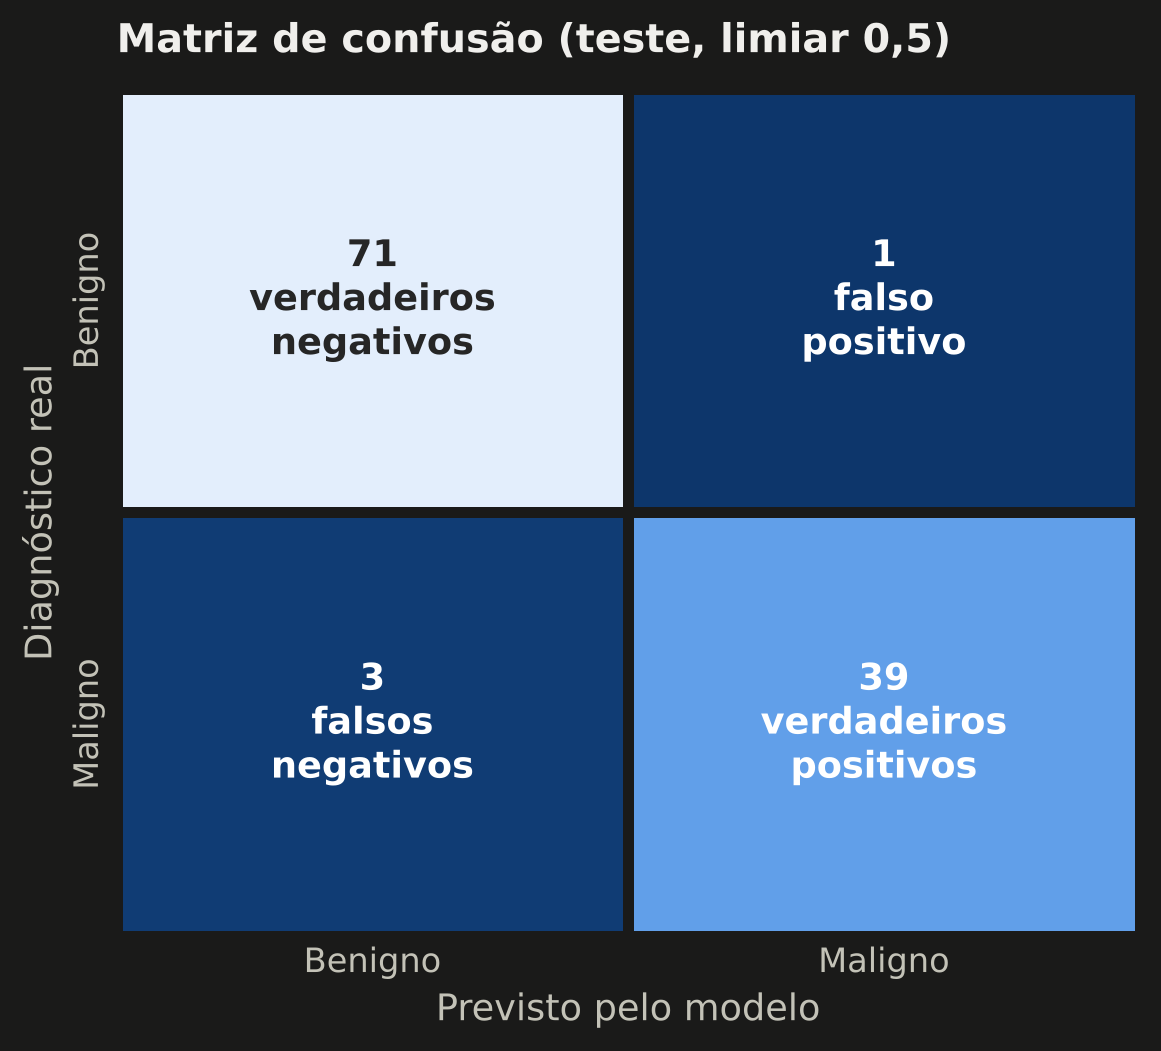

Erros: 3 malignos classificados como benignos (FN) e 1 benigno classificado como maligno (FP)


In [24]:
matriz = confusion_matrix(y_test_c, y_pred_c)
vn, fp, fn, vp = matriz.ravel()
rotulos = np.array([[f"{vn}\nverdadeiros\nnegativos", f"{fp}\nfalso\npositivo" if fp == 1 else f"{fp}\nfalsos\npositivos"],
                    [f"{fn}\nfalsos\nnegativos" if fn != 1 else f"{fn}\nfalso\nnegativo", f"{vp}\nverdadeiros\npositivos"]])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=rotulos, fmt="", cmap=CMAP_SEQ, cbar=False, linewidths=3,
            linecolor=CORES["fundo"], xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES,
            annot_kws={"size": 12, "weight": "bold"}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.set_xlabel("Previsto pelo modelo")
ax.set_ylabel("Diagnóstico real")
ax.set_title("Matriz de confusão (teste, limiar 0,5)")
plt.show()

print(f"Erros: {fn} malignos classificados como benignos (FN) e {fp} benigno classificado como maligno (FP)")

**Análise dos resultados (limiar padrão de 0,5)**

O modelo acertou **110 de 114 exames (acurácia de 96,5%)**, bem acima dos 62,7% de quem chuta sempre "benigno". O AUC de 0,996 mostra que as probabilidades separam as classes quase perfeitamente.

Olhando os erros, que é o que importa:

- **Precision de 0,975:** dos 40 exames que o modelo apontou como malignos, 39 eram mesmo. Houve só **1 falso positivo**. Na prática, um alarme falso leva a exames adicionais, como uma biópsia: é ruim, mas o erro é corrigido depois.
- **Recall de 0,929:** dos 42 tumores malignos do teste, o modelo encontrou 39 e **deixou passar 3**. Esse é o erro grave, porque um paciente com câncer seria tranquilizado indevidamente.

Os resultados no teste ficaram próximos da validação cruzada (acurácia 0,974 e recall 0,953 lá, contra 0,965 e 0,929 aqui), o que indica que o modelo generaliza. Um ponto importante: com 114 exames, cada erro vale quase 1 ponto percentual de acurácia. Então pequenas diferenças entre modelos ou entre execuções não significam muito.

Como o falso negativo é o erro mais caro, o limiar de 0,5 (padrão do `predict`) não é necessariamente o melhor. Testei se baixar esse limiar compensa.

#### Extra: ajuste do limiar de decisão

O modelo devolve uma probabilidade de malignidade, e o `predict` classifica como maligno quando ela passa de 0,5. Baixar o limiar aumenta o recall, à custa de mais falsos positivos. O cuidado aqui é **não escolher o limiar olhando o teste**, porque isso seria trapaça. Uso as previsões "fora da amostra" da validação cruzada no treino: cada exame do treino é previsto por um modelo que não o viu.

O critério que adotei: **o maior limiar que mantém o recall em pelo menos 97,5% na validação cruzada**, ou seja, perder no máximo 1 em cada 40 tumores malignos.

Maior limiar com recall >= 97.5% na validação cruzada: 0.30


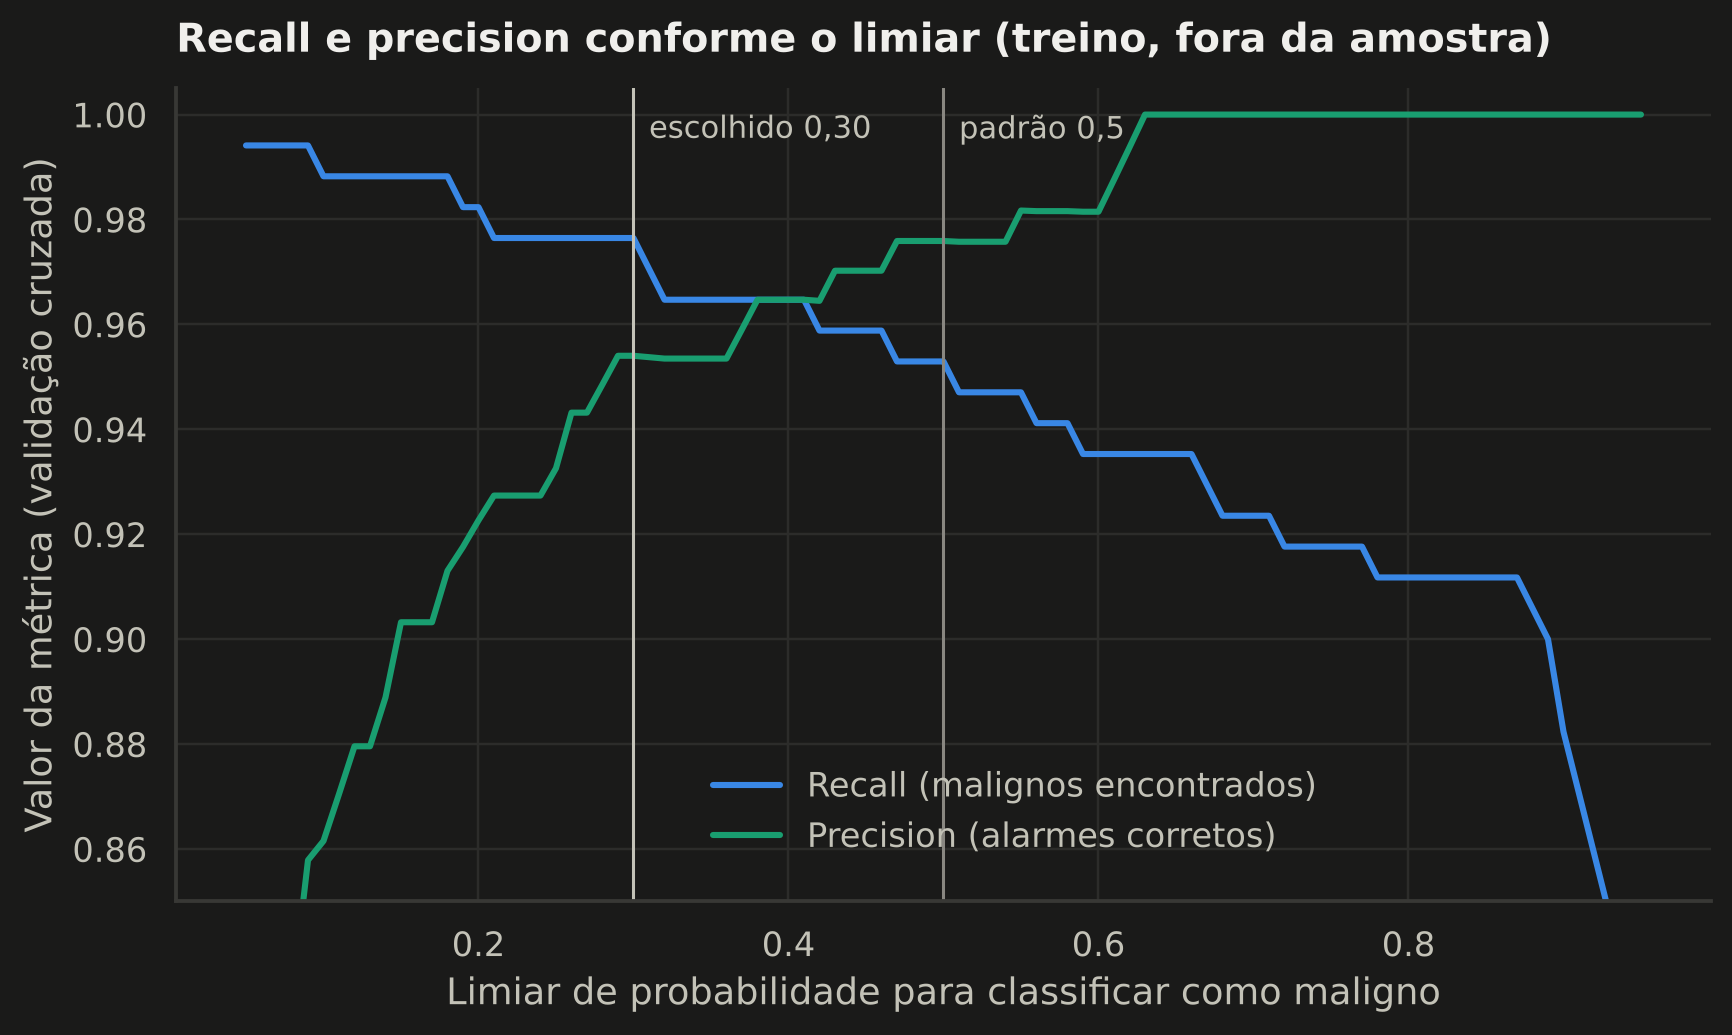

In [25]:
# Probabilidades "fora da amostra" para o treino (cada exame previsto por um modelo que não o viu)
proba_oof = cross_val_predict(modelos["Regressão Logística"], X_train_c, y_train_c,
                              cv=cv_cls, method="predict_proba")[:, 1]

limiares = np.round(np.arange(0.05, 0.951, 0.01), 2)
recall_cv = np.array([recall_score(y_train_c, proba_oof >= t) for t in limiares])
precisao_cv = np.array([precision_score(y_train_c, proba_oof >= t, zero_division=0) for t in limiares])

META_RECALL = 0.975
LIMIAR = float(limiares[recall_cv >= META_RECALL].max())
print(f"Maior limiar com recall >= {META_RECALL:.1%} na validação cruzada: {LIMIAR:.2f}")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(limiares, recall_cv, color=CORES["azul"], label="Recall (malignos encontrados)")
ax.plot(limiares, precisao_cv, color=CORES["verde_agua"], label="Precision (alarmes corretos)")
for limiar, texto in [(0.5, "padrão 0,5"), (LIMIAR, f"escolhido {br(LIMIAR, 2)}")]:
    ax.axvline(limiar, color=CORES["texto_2"] if limiar == LIMIAR else CORES["apagado"], linewidth=1)
    ax.text(limiar + 0.01, 1.0, texto, color=CORES["texto_2"], fontsize=10, va="top")
ax.set_ylim(0.85, 1.005)
ax.set_xlabel("Limiar de probabilidade para classificar como maligno")
ax.set_ylabel("Valor da métrica (validação cruzada)")
ax.set_title("Recall e precision conforme o limiar (treino, fora da amostra)")
ax.legend(loc="lower left", bbox_to_anchor=(0.33, 0.02))
plt.show()

In [26]:
# Aplicando o limiar escolhido no conjunto de teste (só agora o teste é usado)
y_pred_limiar = (proba_teste >= LIMIAR).astype(int)


def resumo_classificacao(y_real, y_prev):
    vn, fp, fn, vp = confusion_matrix(y_real, y_prev).ravel()
    return {"Accuracy": accuracy_score(y_real, y_prev), "Precision": precision_score(y_real, y_prev),
            "Recall": recall_score(y_real, y_prev), "F1-Score": f1_score(y_real, y_prev),
            "Falsos negativos": fn, "Falsos positivos": fp}


comparacao_limiar = pd.DataFrame.from_dict({
    "limiar 0,5 (padrão)": resumo_classificacao(y_test_c, y_pred_c),
    f"limiar {br(LIMIAR, 2)}": resumo_classificacao(y_test_c, y_pred_limiar),
}, orient="index")
display(comparacao_limiar)

# Com que probabilidade o modelo "viu" os malignos que ele errou com o limiar padrão?
perdidos = np.sort(proba_teste[(y_test_c == 1) & (y_pred_c == 0)])
print("Probabilidade de malignidade dos tumores malignos perdidos no limiar 0,5:", np.round(perdidos, 3))

,Accuracy,Precision,Recall,F1-Score,Falsos negativos,Falsos positivos
"limiar 0,5 (padrão)",0.965,0.975,0.929,0.951,3,1
"limiar 0,30",0.982,0.976,0.976,0.976,1,1


Probabilidade de malignidade dos tumores malignos perdidos no limiar 0,5: [0.061 0.315 0.492]


Com o limiar de **0,30**, escolhido só com dados de treino, o resultado no teste melhorou: os falsos negativos caíram de **3 para 1** e os falsos positivos continuaram em 1. O recall subiu de 0,929 para 0,976 sem perda de precision, e a acurácia foi para 98,2%. A melhora no teste confirma que a escolha do limiar não foi sorte da validação.

O tumor maligno que continua sendo perdido recebeu probabilidade de apenas 0,06. O modelo estava "confiante" de que era benigno, e nenhum limiar razoável o recuperaria sem gerar muitos alarmes falsos. É um lembrete de que um modelo assim serve como **apoio** ao diagnóstico, não como substituto do patologista.

### 7.2 Parte 2: métricas no conjunto de teste

- **MAE:** erro absoluto médio, na mesma unidade do alvo (US$ 100 mil).
- **MSE:** média dos erros ao quadrado. Penaliza mais os erros grandes, e a unidade fica "ao quadrado".
- **RMSE:** raiz do MSE, que volta à unidade original. Fica sempre maior ou igual ao MAE, e quanto maior a diferença, mais erros grandes existem.
- **R²:** fração da variação do preço que o modelo explica (1 = perfeito; 0 = igual a prever sempre a média).

In [27]:
y_pred_r = modelo_reg.predict(X_test_r)


def metricas_regressao(y_real, y_prev):
    mse = mean_squared_error(y_real, y_prev)
    return {"MAE": mean_absolute_error(y_real, y_prev), "MSE": mse,
            "RMSE": np.sqrt(mse), "R²": r2_score(y_real, y_prev)}


tabela_reg = pd.DataFrame({
    "Regressão Linear": metricas_regressao(y_test_r, y_pred_r),
    "Baseline (sempre a média)": metricas_regressao(y_test_r, baseline.predict(X_test_r)),
}).T
display(tabela_reg.round(4))

m = tabela_reg.loc["Regressão Linear"]
print(f"MAE  = {m['MAE']:.4f}  -> erro médio de ~US$ {br(m['MAE'] * 100_000, 0)} por região")
print(f"RMSE = {m['RMSE']:.4f}  -> ~US$ {br(m['RMSE'] * 100_000, 0)}")
print(f"R²   = {m['R²']:.4f}  -> o modelo explica ~{100 * m['R²']:.0f}% da variação dos preços")
print(f"Valor médio no teste: US$ {br(y_test_r.mean() * 100_000, 0)} "
      f"(o MAE equivale a {100 * m['MAE'] / y_test_r.mean():.0f}% desse valor)")

,MAE,MSE,RMSE,R²
Regressão Linear,0.533,0.556,0.746,0.576
Baseline (sempre a média),0.906,1.311,1.145,-0.000


MAE  = 0.5332  -> erro médio de ~US$ 53.320 por região
RMSE = 0.7456  -> ~US$ 74.558
R²   = 0.5758  -> o modelo explica ~58% da variação dos preços
Valor médio no teste: US$ 205.500 (o MAE equivale a 26% desse valor)


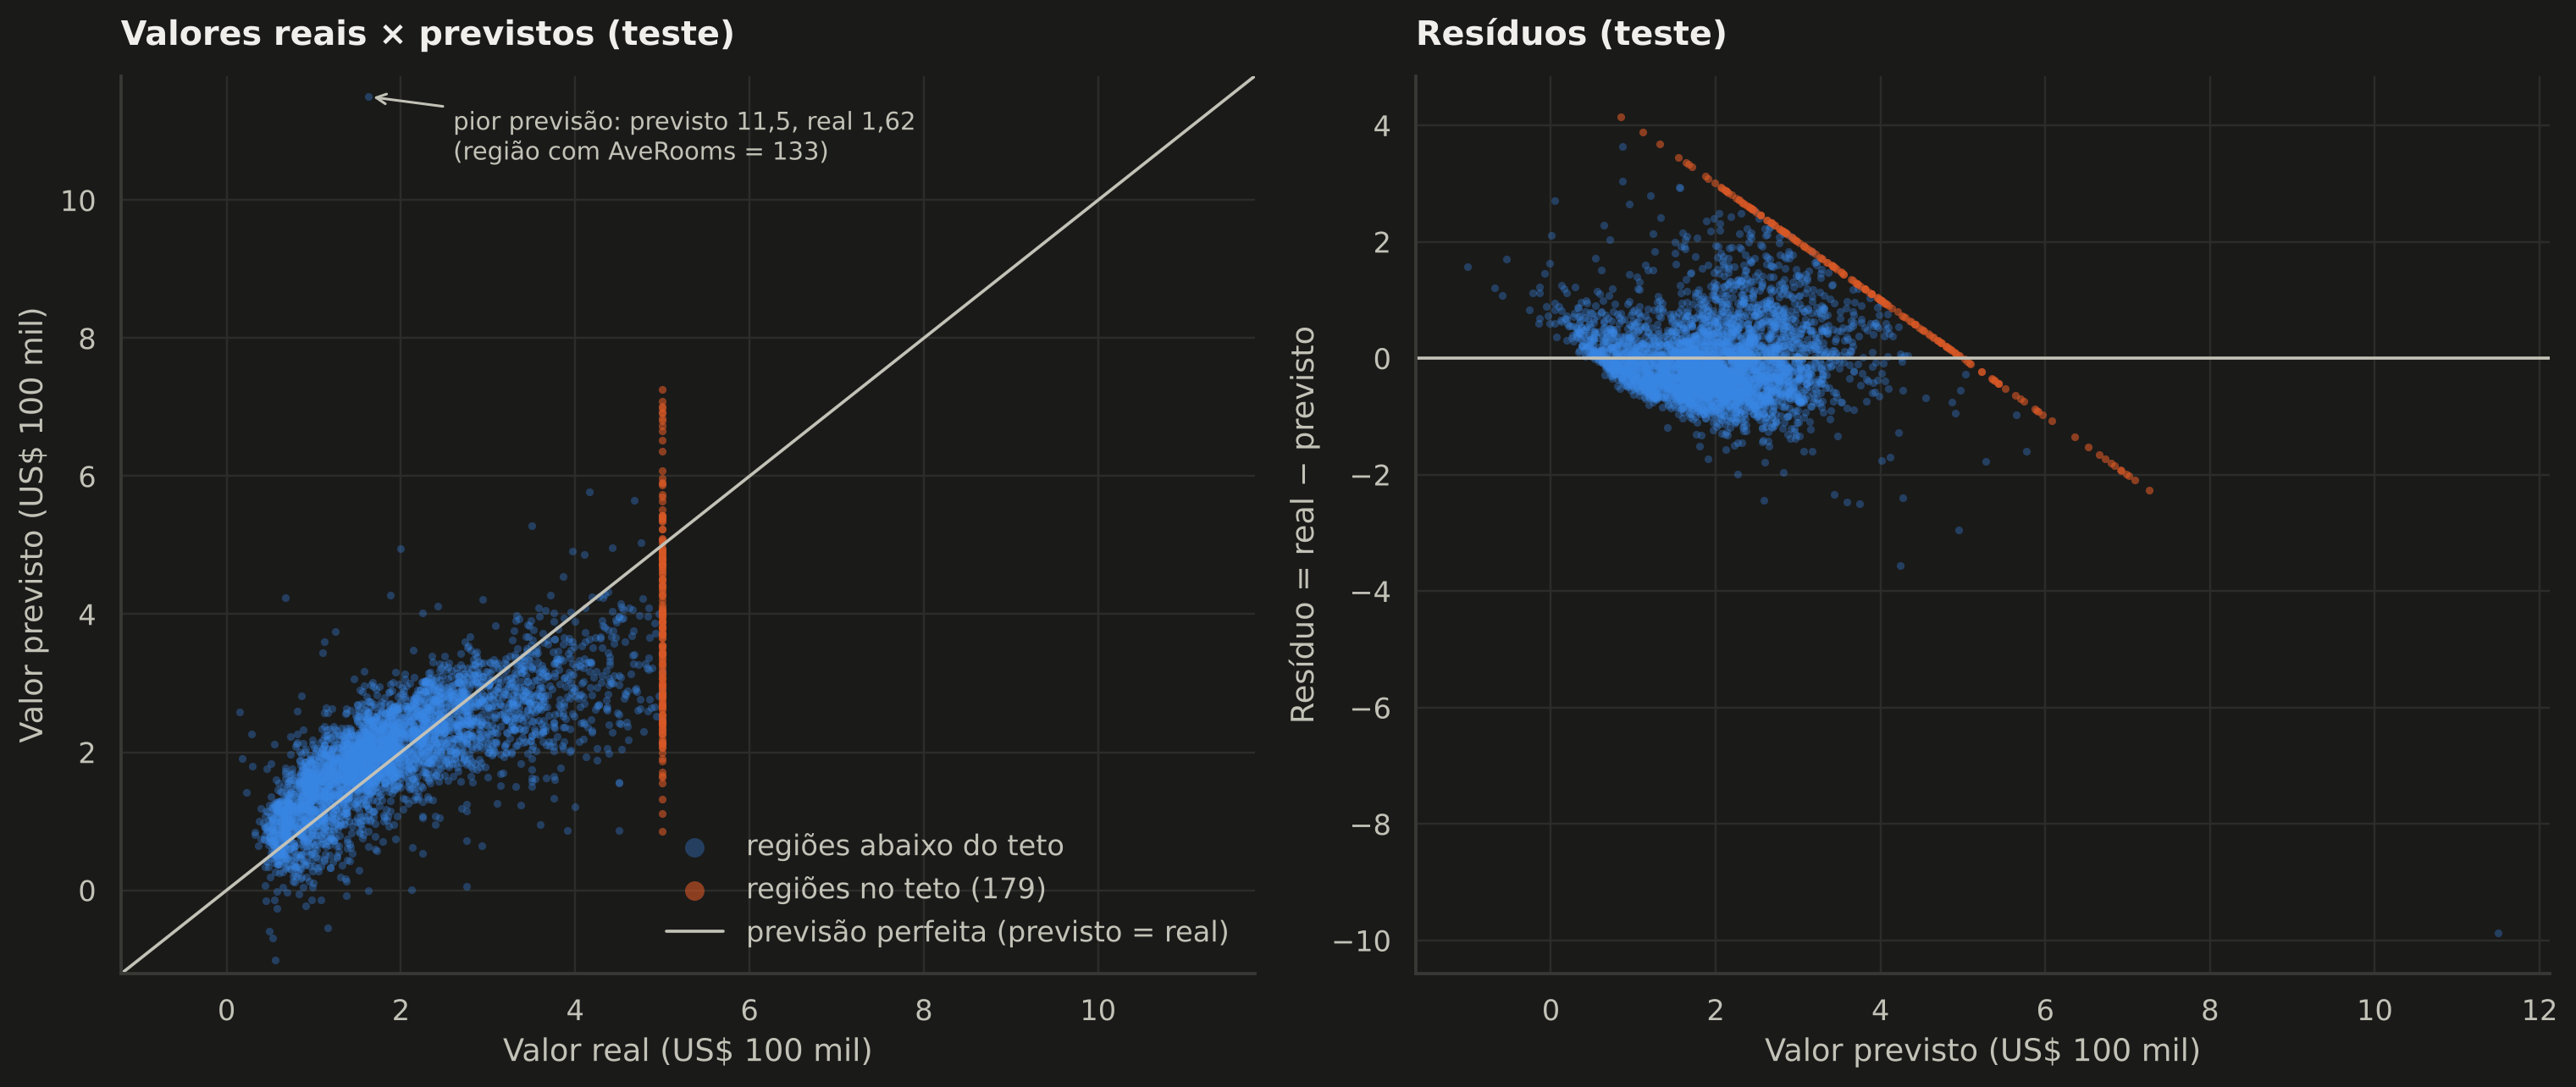

In [28]:
residuos = y_test_r - y_pred_r
no_teto = (y_test_r == TETO).to_numpy()
pior = np.argmax(np.abs(residuos.to_numpy()))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) real x previsto
ax = axes[0]
ax.scatter(y_test_r[~no_teto], y_pred_r[~no_teto], s=9, alpha=0.35, linewidths=0,
           color=CORES["azul"], label="regiões abaixo do teto")
ax.scatter(y_test_r[no_teto], y_pred_r[no_teto], s=9, alpha=0.6, linewidths=0,
           color=CORES["laranja"], label=f"regiões no teto ({no_teto.sum()})")
limites = [min(y_test_r.min(), y_pred_r.min()) - 0.2, max(y_test_r.max(), y_pred_r.max()) + 0.3]
ax.plot(limites, limites, color=CORES["texto_2"], linewidth=1.2, label="previsão perfeita (previsto = real)")
ax.annotate(f"pior previsão: previsto {br(y_pred_r[pior], 1)}, real {br(y_test_r.iloc[pior], 2)}\n"
            f"(região com AveRooms = {br(X_test_r['AveRooms'].iloc[pior], 0)})",
            xy=(y_test_r.iloc[pior], y_pred_r[pior]), xytext=(2.6, 10.9), va="center",
            color=CORES["texto_2"], fontsize=9.5, arrowprops=dict(arrowstyle="->", color=CORES["texto_2"]))
ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_xlabel("Valor real (US$ 100 mil)")
ax.set_ylabel("Valor previsto (US$ 100 mil)")
ax.set_title("Valores reais × previstos (teste)")
ax.legend(loc="lower right", markerscale=2.5)

# (b) resíduos x previsto
ax = axes[1]
ax.scatter(y_pred_r[~no_teto], residuos[~no_teto], s=9, alpha=0.35, linewidths=0, color=CORES["azul"])
ax.scatter(y_pred_r[no_teto], residuos[no_teto], s=9, alpha=0.6, linewidths=0, color=CORES["laranja"])
ax.axhline(0, color=CORES["texto_2"], linewidth=1.2)
ax.set_xlabel("Valor previsto (US$ 100 mil)")
ax.set_ylabel("Resíduo = real − previsto")
ax.set_title("Resíduos (teste)")

fig.tight_layout()
plt.show()

In [29]:
# Erro separado: regiões no teto x demais
erro_grupos = pd.DataFrame({
    "regiões": [no_teto.sum(), (~no_teto).sum()],
    "MAE": [mean_absolute_error(y_test_r[no_teto], y_pred_r[no_teto]),
            mean_absolute_error(y_test_r[~no_teto], y_pred_r[~no_teto])],
    "resíduo médio (real − previsto)": [residuos[no_teto].mean(), residuos[~no_teto].mean()],
}, index=["no teto (US$ 500 mil+)", "abaixo do teto"])
display(erro_grupos)

# O erro muda conforme a faixa de preço real?
faixas_preco = pd.cut(y_test_r, bins=[0, 1, 2, 3, 4, TETO], labels=["até 1", "1 a 2", "2 a 3", "3 a 4", "4 a 5 (inclui teto)"])
display(pd.DataFrame({"resíduo": residuos, "faixa de valor real (US$ 100 mil)": faixas_preco})
        .groupby("faixa de valor real (US$ 100 mil)", observed=True)["resíduo"]
        .agg(regiões="count", **{"resíduo médio": "mean", "desvio do resíduo": "std"}))

print(f"Previsões negativas (impossíveis): {(y_pred_r < 0).sum()}")
print(f"Previsões acima do teto de 5,0:    {(y_pred_r > TETO).sum()}")

# Quanto um único ponto extremo pesa no R²?
sem_pior = np.ones(len(y_test_r), dtype=bool)
sem_pior[pior] = False
print(f"\nPior previsão: região com {X_test_r['Population'].iloc[pior]:.0f} moradores, "
      f"AveRooms = {X_test_r['AveRooms'].iloc[pior]:.1f}, lat/long = "
      f"({X_test_r['Latitude'].iloc[pior]}, {X_test_r['Longitude'].iloc[pior]})")
print(f"R² com todos os pontos:     {r2_score(y_test_r, y_pred_r):.3f}")
print(f"R² sem essa única região:   {r2_score(y_test_r[sem_pior], y_pred_r[sem_pior]):.3f}")

,regiões,MAE,resíduo médio (real − previsto)
no teto (US$ 500 mil+),179,1.496,1.128
abaixo do teto,3949,0.490,-0.047


,regiões,resíduo médio,desvio do resíduo
faixa de valor real (US$ 100 mil),,,
até 1,739,-0.310,0.467
1 a 2,1682,-0.284,0.510
2 a 3,956,0.044,0.493
3 a 4,412,0.670,0.614
4 a 5 (inclui teto),339,1.191,1.134


Previsões negativas (impossíveis): 15
Previsões acima do teto de 5,0:    39

Pior previsão: região com 36 moradores, AveRooms = 132.5, lat/long = (38.8, -120.08)
R² com todos os pontos:     0.576
R² sem essa única região:   0.594


#### Extra: comparação com um modelo não linear

Para saber se o erro que sobra vem de "ruído" nos dados ou da limitação do modelo linear, treinei um modelo não linear (`HistGradientBoostingRegressor`, com os parâmetros padrão) nos mesmos dados. Ele não faz parte do que foi pedido: serve só como **referência** para a análise.

In [30]:
referencia = HistGradientBoostingRegressor(random_state=SEED).fit(X_train_r, y_train_r)
tabela_ref = pd.DataFrame({
    "Regressão Linear": metricas_regressao(y_test_r, y_pred_r),
    "Gradient Boosting (referência)": metricas_regressao(y_test_r, referencia.predict(X_test_r)),
}).T
tabela_ref.round(4)

,MAE,MSE,RMSE,R²
Regressão Linear,0.533,0.556,0.746,0.576
Gradient Boosting (referência),0.311,0.217,0.465,0.835


**Interpretação dos resultados da regressão**

- **O modelo aprende algo útil:** R² de **0,576** no teste, contra 0 do baseline. O RMSE caiu de 1,145 para **0,746**. Em dinheiro, o erro médio absoluto (MAE) é de cerca de **US$ 53 mil** por região, e o RMSE fica em torno de **US$ 75 mil**.
- **Mas o erro ainda é grande** para quem quisesse usar isso para precificar: o MAE equivale a uns 26% do valor médio das regiões do teste. O modelo explica pouco mais da metade da variação dos preços.
- **O gráfico real × previsto mostra os problemas:**
  1. **Teto:** os pontos laranja formam uma coluna vertical em 5,0. São regiões que valem "US$ 500 mil ou mais", e as previsões do modelo para elas vão de menos de 1 até mais de 7. O MAE nesse grupo (~1,50) é cerca de 3 vezes o das demais regiões (~0,49), e o modelo as **subestima** em média (resíduo médio de +1,13). No gráfico de resíduos, elas formam a diagonal laranja, porque o resíduo delas é exatamente 5 − previsto.
  2. **O modelo "puxa" tudo para o meio:** pela tabela de faixas, ele superestima as regiões baratas (resíduo médio de −0,31 abaixo de US$ 100 mil) e subestima as caras (+0,67 entre 3 e 4 e +1,19 acima de 4). A dispersão dos resíduos também aumenta nas faixas caras: o desvio vai de ~0,47 nas regiões abaixo de US$ 100 mil para ~0,61 entre 3 e 4, e passa de 1,1 na última faixa (que inclui o teto). Esse padrão é sinal de que a relação não é linear, e a reta acaba sendo um meio-termo.
  3. **Previsões impossíveis:** 15 previsões negativas e 39 acima de 5,0. Uma reta não "sabe" que preço não pode ser negativo.
  4. **Sensibilidade a valores extremos:** a pior previsão é uma região com só 36 moradores e 132 cômodos por domicílio (perto do Lago Tahoe, provavelmente casas de veraneio). O modelo previu US$ 1,15 milhão para uma região de US$ 162 mil. **Essa única região derruba o R² de 0,594 para 0,576.**
- **A limitação é do modelo, não dos dados:** o R² da validação cruzada (~0,61) é parecido com o do treino, então não há sobreajuste. Já o modelo não linear de referência chegou a **R² ≈ 0,83 e MAE ≈ US$ 31 mil** com os mesmos dados. Boa parte do erro da Regressão Linear vem de ela não conseguir representar o efeito da localização e as relações curvas.

## 8. Conclusão

**Parte 1: classificação.** A Regressão Logística com padronização classificou corretamente **96,5% dos exames de teste**, com precision de 0,975 e recall de 0,929 para tumores malignos. Os resultados ficaram coerentes com a validação cruzada, então o desempenho não é fruto de uma divisão favorável. A comparação entre os quatro algoritmos mostrou que, neste dataset, a escolha do algoritmo importa menos do que parece. Regressão Logística, Random Forest e KNN ficaram dentro da margem de variação uns dos outros. Só a Árvore de Decisão ficou claramente para trás.

O ponto que considero mais importante é que **acurácia não é a métrica certa para guiar esse problema**. Com o limiar padrão, o modelo deixava passar 3 dos 42 tumores malignos. Ajustando o limiar para 0,30, escolhido só com o treino para não contaminar o teste, os falsos negativos caíram para 1 sem aumentar os falsos positivos. Ainda assim, um caso maligno recebeu probabilidade de apenas 6%. Com isso em mente, eu limitaria as conclusões a três pontos:

- O dataset é **pequeno** (569 exames) e vem de **uma única instituição**. Não há garantia de que o desempenho se repita com imagens de outros equipamentos ou laboratórios.
- O conjunto de teste tem só 114 exames, e **cada erro muda a acurácia em quase 1 ponto percentual**. Diferenças pequenas entre modelos não devem ser levadas muito a sério.
- Um modelo assim pode ajudar na triagem (por exemplo, priorizar casos para revisão), mas **não substitui** a avaliação médica.

**Parte 2: regressão.** A Regressão Linear explicou cerca de **58% da variação dos preços** (R² = 0,576), com MAE de 0,533 (≈ US$ 53 mil) e RMSE de 0,746 (≈ US$ 75 mil). É bem melhor que prever sempre a média, mas o erro é alto para uso prático. A análise mostrou por quê:

- A variável mais importante é a renda (`MedInc`), mas o preço também depende muito da **localização**, e de um jeito não linear (litoral e grandes cidades), o que uma reta não consegue capturar.
- O **teto de US$ 500 mil** distorce o alvo: o modelo erra bastante nessas regiões, e a métrica nem é totalmente justa, porque o valor real delas é desconhecido.
- A Regressão Linear é **sensível a valores extremos**: uma única região atípica derrubou o R² de 0,594 para 0,576. Ela também gerou previsões impossíveis (preços negativos).
- O modelo não linear de referência chegou a R² ≈ 0,83 nos mesmos dados. Isso mostra que ainda há bastante informação nos atributos que o modelo linear não aproveita.

Também é preciso lembrar que os dados são de **1990** e descrevem **regiões, não casas**. Mesmo um modelo perfeito aqui não serviria para avaliar um imóvel específico hoje.

**Comparando as duas partes:** o mesmo tipo de modelo (linear) funcionou muito bem num problema e só razoavelmente no outro. A diferença está nos dados: no câncer de mama, as classes já são quase separáveis por uma combinação linear dos atributos. Nos imóveis, a relação com o preço é curva e depende da localização. Se eu fosse continuar o trabalho, os próximos passos seriam:

- na Parte 1, validar com mais dados e calibrar o limiar junto com especialistas;
- na Parte 2, testar transformações (log do preço, atributos de distância até a costa ou às grandes cidades), tratar os valores extremos e comparar com modelos não lineares de forma mais completa.